## Setup: Mount Google Drive

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


## Load Models, TF-IDF, Scaler, and Enron Test Data

In [ ]:
import pandas as pd
import numpy as np
import joblib
import re
import json
import math
import time
import random

from collections import Counter
from scipy.sparse import hstack, vstack

import matplotlib.pyplot as plt

import shap
shap.initjs()


svm_linear_model = joblib.load(
    "/content/drive/MyDrive/Phishing_Email/models/nlp_svm_linear_model.pkl"
)

svm_kernel_model = joblib.load(
    "/content/drive/MyDrive/Phishing_Email/models/nlp_svm_kernel_model.pkl"
)

rf_model = joblib.load(
    "/content/drive/MyDrive/Phishing_Email/models/nlp_rf_model.pkl"
)


tfid = joblib.load(
    "/content/drive/MyDrive/Phishing_Email/nlp_features/tfidf_features.pkl"
)

nlp_scaler = joblib.load(
    "/content/drive/MyDrive/Phishing_Email/nlp_features/nlp_scaler.pkl"
)

nlp_feature_names = joblib.load(
    "/content/drive/MyDrive/Phishing_Email/nlp_features/nlp_feature_names.pkl"
)


tfidf_feature_names = tfid.get_feature_names_out().tolist()
all_feature_names = tfidf_feature_names + nlp_feature_names


print("=" * 60)
print("Models and feature objects loaded successfully!")
print("=" * 60)

print(f"SVM Linear Model : {type(svm_linear_model)}")
print(f"SVM Kernel Model : {type(svm_kernel_model)}")
print(f"Random Forest    : {type(rf_model)}")
print(f"TF-IDF Features  : {len(tfidf_feature_names)}")
print(f"NLP Features     : {len(nlp_feature_names)}")
print(f"Total Features   : {len(all_feature_names)}")
print("=" * 60)

Models and feature objects loaded successfully!
SVM Linear Model : <class 'sklearn.svm._classes.LinearSVC'>
SVM Kernel Model : <class 'sklearn.svm._classes.SVC'>
Random Forest    : <class 'sklearn.ensemble._forest.RandomForestClassifier'>
TF-IDF Features  : 5000
NLP Features     : 9
Total Features   : 5009


## Text Pre-processing and Feature Engineering Pipeline

In [ ]:
import re
import html
import string
def preprocess_text(text):
    text = html.unescape(text)
    text = text.lower()
    text = re.sub(r'<.*?>', ' ', text)
    text = re.sub(r'https?://\S+|www\.\S+', ' ', text)
    text = re.sub(r'\S+@\S+', ' ', text)
    text = re.sub(r'\b(?:\d{1,3}\.){3}\d{1,3}\b', ' ', text)
    text = re.sub(r'\d+', ' ', text)
    text = text.translate(str.maketrans('', '', string.punctuation))
    text = re.sub(r'[^a-z\s]', ' ', text)
    text = re.sub(r'(.)\1{2,}', r'\1\1', text)
    text = re.sub(r'\s+', ' ', text).strip()
    return text
def extract_nlp_features(precomputed_row: dict):
    """
    Accepts a dict (or pd.Series row) with the precomputed NLP feature columns
    that already exist in Enron_preprocessed.csv.
    Falls back to zeros for missing columns - all features are present in the saved CSV.
    """
    features = {col: float(precomputed_row.get(col, 0)) for col in nlp_feature_names}
    features_df = pd.DataFrame([features])
    scaled_features = nlp_scaler.transform(features_df[nlp_feature_names])
    return scaled_features
def get_combined_features(email_text, precomputed_row=None):
    """
    email_text       : raw/clean email body text (used for TF-IDF).
    precomputed_row  : dict or pd.Series of precomputed NLP feature values
                       from Enron_preprocessed.csv.  If None, falls back
                       to zeros (only for ad-hoc inference on emails not in
                       the test CSV, e.g. adversarial variants).
    """
    processed_text = preprocess_text(email_text)
    tfidf_vector = tfid.transform([processed_text])
    if precomputed_row is not None:
        nlp_features = extract_nlp_features(precomputed_row)
    else:
        zero_row = {col: 0 for col in nlp_feature_names}
        features_df = pd.DataFrame([zero_row])
        nlp_features = nlp_scaler.transform(features_df[nlp_feature_names])
    return hstack([tfidf_vector, nlp_features])
print("Feature engineering pipeline ready (improved preprocessing).")
print("Note: NLP features are read from the preprocessed CSV - no recomputation.")

Feature engineering pipeline ready (improved preprocessing).
Note: NLP features are read from the preprocessed CSV - no recomputation.


## Load and Prepare Enron Evaluation Dataset

In [ ]:
test_df = pd.read_csv("/content/drive/MyDrive/Phishing_Email/final_dataset/Enron_preprocessed.csv")
if "clean_text" in test_df.columns and "body" not in test_df.columns:
    test_df = test_df.rename(columns={"clean_text": "body"})
    print("Renamed 'clean_text' column to 'body'.")
EMAIL_COLUMN = "body"
LABEL_COLUMN = "label"
nlp_num_cols = [
    "word_count", "avg_word_length", "uppercase_ratio", "url_like_count",
    "text_entropy", "action_density", "has_attachment",
    "repeated_char_patterns", "writing_error_total"
]
for col in nlp_num_cols:
    if col in test_df.columns:
        test_df[col] = test_df[col].fillna(0)
test_df[EMAIL_COLUMN] = test_df[EMAIL_COLUMN].astype(str)
unique_labels = test_df[LABEL_COLUMN].unique()
print("Unique label values:", unique_labels)
if set(unique_labels) <= {0, 1, "0", "1", 0.0, 1.0}:
    test_df[LABEL_COLUMN] = test_df[LABEL_COLUMN].astype(int)
elif set(str(v).lower() for v in unique_labels) <= {"phishing", "legitimate", "spam", "ham", "benign"}:
    label_str_map = {v: (1 if str(v).lower() in ("phishing","spam") else 0)
                     for v in unique_labels}
    test_df[LABEL_COLUMN] = test_df[LABEL_COLUMN].map(label_str_map)
print(f"Test set size: {len(test_df)}")
print(f"Label distribution:\n{test_df[LABEL_COLUMN].value_counts()}")
background_sample = test_df.sample(n=min(100, len(test_df)), random_state=42)
background_emails = background_sample[EMAIL_COLUMN].tolist()
background_sparse = vstack([
    get_combined_features(email, row)
    for email, (_, row) in zip(background_emails, background_sample.iterrows())
])
background_dense = background_sparse.toarray()
SVM_LINEAR_KERNEL_NSAMPLES = 100
svm_explainer = shap.LinearExplainer(
    svm_linear_model,
    background_sparse
)
KERNEL_SHAP_NSAMPLES = 100
svm_kernel_background = shap.kmeans(background_dense, 25)
svm_kernel_explainer = shap.KernelExplainer(
    svm_kernel_model.predict_proba,
    svm_kernel_background
)
rf_explainer = shap.TreeExplainer(
    rf_model,
    data=background_dense,
    model_output="probability"
)
background_data = {
    "svm":        background_sparse,
    "svm_kernel": background_dense,
    "rf":         background_dense
}
print(f"Background dense shape: {background_dense.shape}")
print(f"Background sparse shape: {background_sparse.shape}")
print("SHAP explainers ready (SVM linear, SVM kernel, Random Forest)")

Renamed 'clean_text' column to 'body'.
Unique label values: [0 1]
Test set size: 28256
Label distribution:
label
0    14536
1    13720
Name: count, dtype: int64
Background dense shape: (100, 5009)
Background sparse shape: (100, 5009)
SHAP explainers ready (SVM linear, SVM kernel, Random Forest)


## Core ML Functions and SHAP Consistency Helpers

In [ ]:
def _get_svm_prob_phishing(X_sparse):
    """Raw P(phishing) from SVM sigmoid. Never inverted."""
    score = svm_linear_model.decision_function(X_sparse)[0]
    return float(1.0 / (1.0 + np.exp(-score)))
def _get_svm_kernel_prob_phishing(X_dense):
    """Raw P(phishing) from kernel SVM predict_proba[:,1].
    FIX: accepts dense array - kernel SVM requires dense input.
    """
    return float(svm_kernel_model.predict_proba(X_dense)[0][1])
def _get_rf_prob_phishing(X_dense):
    """Raw P(phishing) = predict_proba[1]. Never inverted."""
    return float(rf_model.predict_proba(X_dense)[0][1])
MODEL_WEIGHTS = {
    "svm_linear": 0.35,
    "svm_kernel": 0.40,
    "rf":         0.25,
}
PHISHING_THRESHOLD = 0.5
def compute_final_verdict(svm_label, svm_prob, svm_kernel_label, svm_kernel_prob,
                           rf_label, rf_prob,
                           weights=MODEL_WEIGHTS, threshold=PHISHING_THRESHOLD):
    """
    Weighted probability averaging across SVM (linear), SVM (kernel), and RF.
    FIX: svm_prob / svm_kernel_prob / rf_prob must be raw P(Phishing) in [0,1]
    - never "confidence in the model's own prediction". Callers that previously
    passed `proba[pred]` (which flips below-0.5 probs) now use the corrected
    _get_*_prob_phishing() helpers instead.
    """
    svm_p   = svm_prob   / 100 if svm_prob   > 1 else float(svm_prob)
    kern_p  = svm_kernel_prob / 100 if svm_kernel_prob > 1 else float(svm_kernel_prob)
    rf_p    = rf_prob    / 100 if rf_prob    > 1 else float(rf_prob)
    blended = (
        weights["svm_linear"] * svm_p +
        weights["svm_kernel"] * kern_p +
        weights["rf"]         * rf_p
    )
    final_label = "Phishing" if blended >= threshold else "Legitimate"
    final_confidence = round(50 + abs(blended - 0.5) * 100, 1)
    models_agree = (svm_label == final_label and
                    svm_kernel_label == final_label and
                    rf_label == final_label)
    majority_count = sum([svm_label == final_label,
                          svm_kernel_label == final_label,
                          rf_label == final_label])
    return {
        "final_label":      final_label,
        "final_confidence": final_confidence,
        "models_agree":     models_agree,
        "majority_count":   majority_count,
        "blended_prob":     round(blended * 100, 1),
    }
def compute_shap_values(combined_features_dense, combined_features_sparse):
    def safe_shap(vals):
        arr = np.asarray(vals).squeeze()
        if isinstance(vals, list) and len(vals) > 1:
            arr = np.asarray(vals[1]).squeeze()
        if arr.ndim > 1:
            arr = arr[..., -1] if arr.shape[-1] in [1, 2] else arr.flatten()
        return np.asarray(arr, dtype=float).ravel()
    svm_shap        = safe_shap(svm_explainer.shap_values(
        combined_features_sparse
    ))
    svm_kernel_shap = safe_shap(svm_kernel_explainer.shap_values(
        combined_features_dense, nsamples=KERNEL_SHAP_NSAMPLES
    ))
    rf_shap         = safe_shap(rf_explainer.shap_values(combined_features_dense, check_additivity=False))
    def get_top_features(shap_vals, top_n=20):
        pairs    = list(zip(all_feature_names, shap_vals))
        top_pos  = sorted(pairs, key=lambda x: x[1],  reverse=True)[:top_n]
        top_neg  = sorted(pairs, key=lambda x: x[1])[:top_n]
        return top_pos, top_neg
    svm_top_pos,        svm_top_neg        = get_top_features(svm_shap)
    svm_kernel_top_pos, svm_kernel_top_neg = get_top_features(svm_kernel_shap)
    rf_top_pos,         rf_top_neg         = get_top_features(rf_shap)
    def pairwise_raw_overlap(pos_a, pos_b, top_n=20):
        set_a = {f for f, _ in pos_a}
        set_b = {f for f, _ in pos_b}
        return round(len(set_a & set_b) / top_n * 100, 1)
    raw_overlap_svm_rf     = pairwise_raw_overlap(svm_top_pos, rf_top_pos)
    raw_overlap_svm_kernel = pairwise_raw_overlap(svm_top_pos, svm_kernel_top_pos)
    raw_overlap_kernel_rf  = pairwise_raw_overlap(svm_kernel_top_pos, rf_top_pos)
    pair_svm_rf     = _pairwise_enhanced(svm_shap, rf_shap, all_feature_names)
    pair_svm_kernel = _pairwise_enhanced(svm_shap, svm_kernel_shap, all_feature_names)
    pair_kernel_rf  = _pairwise_enhanced(svm_kernel_shap, rf_shap, all_feature_names)
    def _avg3(key):
        return np.mean([pair_svm_rf[key], pair_svm_kernel[key], pair_kernel_rf[key]])
    weighted_jaccard  = round(_avg3("weighted_jaccard")  * 100, 1)
    rank_correlation  = round(_avg3("rank_correlation")  * 100, 1)
    cosine_similarity = round(_avg3("cosine_similarity") * 100, 1)
    topk_stability    = round(_avg3("topk_stability")    * 100, 1)
    shap_consistency = round(
        np.mean([_avg3(k) for k in
                 ("weighted_jaccard","rank_correlation","cosine_similarity","topk_stability")]) * 100, 1
    )
    return {
        "svm_shap": svm_shap, "svm_kernel_shap": svm_kernel_shap, "rf_shap": rf_shap,
        "svm_top_pos": svm_top_pos, "svm_top_neg": svm_top_neg,
        "svm_kernel_top_pos": svm_kernel_top_pos, "svm_kernel_top_neg": svm_kernel_top_neg,
        "rf_top_pos":  rf_top_pos,  "rf_top_neg":  rf_top_neg,
        "shap_consistency":      shap_consistency,
        "raw_overlap_svm_rf":    raw_overlap_svm_rf,
        "raw_overlap_svm_kernel": raw_overlap_svm_kernel,
        "raw_overlap_kernel_rf": raw_overlap_kernel_rf,
        "weighted_jaccard":      weighted_jaccard,
        "rank_correlation":      rank_correlation,
        "cosine_similarity":     cosine_similarity,
        "topk_stability":        topk_stability,
    }
def compute_explanation_confidence(svm_label, svm_kernel_label, rf_label,
                                   svm_prob, svm_kernel_prob, rf_prob,
                                   concept_agreement_score, shap_consistency):
    votes = [svm_label, svm_kernel_label, rf_label]
    _, majority_count = Counter(votes).most_common(1)[0]
    prediction_agreement = round(majority_count / 3 * 100, 1)
    probs = [
        svm_prob   / 100 if svm_prob   > 1 else svm_prob,
        svm_kernel_prob / 100 if svm_kernel_prob > 1 else svm_kernel_prob,
        rf_prob    / 100 if rf_prob    > 1 else rf_prob,
    ]
    probability_similarity = round((1 - (max(probs) - min(probs))) * 100, 1)
    overall_confidence = round(
        prediction_agreement   * 0.25 +
        probability_similarity * 0.25 +
        concept_agreement_score * 0.25 +
        shap_consistency        * 0.25, 1
    )
    return {
        "prediction_agreement":  prediction_agreement,
        "probability_similarity": probability_similarity,
        "concept_agreement":     concept_agreement_score,
        "shap_consistency":      shap_consistency,
        "overall_confidence":    overall_confidence,
    }
from scipy.stats import spearmanr
def _weighted_jaccard(v1, v2, feature_names, top_n=20):
    """
    Weighted Jaccard between the top-n positive SHAP features of two models.
    Weight = |shap_val|, normalised to sum=1 per model. Returns value in [0,1].
    """
    pairs1 = sorted(zip(feature_names, v1), key=lambda x: x[1], reverse=True)[:top_n]
    pairs2 = sorted(zip(feature_names, v2), key=lambda x: x[1], reverse=True)[:top_n]
    w1 = {f: abs(s) for f, s in pairs1}
    w2 = {f: abs(s) for f, s in pairs2}
    sum1, sum2 = sum(w1.values()) or 1, sum(w2.values()) or 1
    w1 = {f: v / sum1 for f, v in w1.items()}
    w2 = {f: v / sum2 for f, v in w2.items()}
    all_feats    = set(w1) | set(w2)
    intersection = sum(min(w1.get(f, 0), w2.get(f, 0)) for f in all_feats)
    union        = sum(max(w1.get(f, 0), w2.get(f, 0)) for f in all_feats)
    return intersection / union if union > 0 else 0.0
def _rank_correlation(v1, v2):
    """
    Spearman rank correlation on the full signed SHAP vectors.
    Mapped from [-1,1] to [0,1] as (rho+1)/2.
    """
    rho, _ = spearmanr(v1, v2)
    if np.isnan(rho):
        rho = 0.0
    return (float(rho) + 1.0) / 2.0
def _cosine_similarity(v1, v2):
    """
    Cosine similarity between two full signed SHAP vectors.
    Mapped from [-1,1] to [0,1] as (cos+1)/2.
    """
    norm1, norm2 = np.linalg.norm(v1), np.linalg.norm(v2)
    if norm1 == 0 or norm2 == 0:
        return 0.5
    cos = float(np.dot(v1, v2) / (norm1 * norm2))
    return (cos + 1.0) / 2.0
def _topk_stability(v1, v2, feature_names, k_values=(5, 10, 15, 20, 25, 30)):
    """
    Average Jaccard of top-k positive feature sets across multiple k values.
    Measures sensitivity to the choice of k. Returns value in [0,1].
    """
    jaccards = []
    for k in k_values:
        set1 = {f for f, _ in sorted(zip(feature_names, v1),
                                      key=lambda x: x[1], reverse=True)[:k]}
        set2 = {f for f, _ in sorted(zip(feature_names, v2),
                                      key=lambda x: x[1], reverse=True)[:k]}
        union = set1 | set2
        jaccards.append(len(set1 & set2) / len(union) if union else 0.0)
    return float(np.mean(jaccards))
def _pairwise_enhanced(v_a, v_b, feature_names, top_n=20):
    """Compute all four enhanced metrics for one model pair."""
    return {
        "weighted_jaccard":  _weighted_jaccard(v_a, v_b, feature_names, top_n),
        "rank_correlation":  _rank_correlation(v_a, v_b),
        "cosine_similarity": _cosine_similarity(v_a, v_b),
        "topk_stability":    _topk_stability(v_a, v_b, feature_names),
    }
print("Enhanced SHAP consistency helpers loaded (scipy.stats.spearmanr).")
print("Core ML functions ready (fixed probability semantics + Weighted Probability Averaging).")
print(f"  Weights  : SVM-linear={MODEL_WEIGHTS['svm_linear']}, "
      f"SVM-kernel={MODEL_WEIGHTS['svm_kernel']}, RF={MODEL_WEIGHTS['rf']}")
print(f"  Threshold: {PHISHING_THRESHOLD}")

Enhanced SHAP consistency helpers loaded (scipy.stats.spearmanr).
Core ML functions ready (fixed probability semantics + Weighted Probability Averaging).
  Weights  : SVM-linear=0.35, SVM-kernel=0.4, RF=0.25
  Threshold: 0.5


## Rule-Based Phishing Concept Explainer

In [ ]:
import json
import os
KB_PATH = "/content/drive/MyDrive/Phishing_Email/notebooks/phishing_explanation_kb.json"
_kb_cache = None
def load_kb(path=KB_PATH):
    """Load (and cache) the explanation knowledge base from disk."""
    global _kb_cache
    if _kb_cache is None:
        if not os.path.exists(path):
            raise FileNotFoundError(
                f"Knowledge base not found at '{path}'. "
                f"Upload phishing_explanation_kb.json or update KB_PATH."
            )
        with open(path, "r", encoding="utf-8") as f:
            _kb_cache = json.load(f)
    return _kb_cache
DEFAULT_EXPLANATIONS = {
    "bidirectional": "No dominant pattern could be matched to the knowledge base.",
    "contrastive": "No dominant pattern could be matched to the knowledge base.",
    "counterfactual": "No dominant pattern could be matched to the knowledge base.",
}
DEFAULT_RECOMMENDATIONS = [
    "Avoid clicking suspicious links.",
    "Do not share credentials.",
]
def _match_concept(feature_name, kb):
    """
    Try to map a single SHAP feature name to:
      - a named "concept" (text-pattern based, e.g. 'Urgency / Pressure Language'), or
      - an NLP meta-feature explanation (e.g. 'url_like_count'), or
      - None if nothing matches.
    Returns (kind, name, payload) where kind is "concept" or "nlp_feature",
    and payload is the matched concept dict / nlp-feature dict.
    """
    fname = str(feature_name).lower().strip()
    nlp_bank = kb.get("nlp_feature_explanations", {})
    if fname in nlp_bank:
        return ("nlp_feature", fname, nlp_bank[fname])
    for concept in kb.get("concepts", []):
        if fname in concept.get("keywords", []):
            return ("concept", concept["name"], concept)
    for concept in kb.get("concepts", []):
        keywords = concept.get("keywords", [])
        if any(kw in fname or fname in kw for kw in keywords if len(kw) > 3):
            return ("concept", concept["name"], concept)
    return (None, None, None)
def _extract_concepts(top_pos, top_neg, kb, max_per_direction=10):
    """
    Given a model's top positive (phishing-leaning) and top negative
    (legitimate-leaning) SHAP feature/value pairs, return:
      phishing_concepts, legit_concepts  -> lists of concept names
      phishing_nlp_phrases, legit_nlp_phrases -> short noun phrases from nlp features
    """
    phishing_concepts, legit_concepts = [], []
    phishing_nlp, legit_nlp = [], []
    for fname, shap_val in top_pos[:max_per_direction]:
        if shap_val <= 0:
            continue
        kind, name, payload = _match_concept(fname, kb)
        if kind == "concept" and name not in phishing_concepts:
            phishing_concepts.append(name)
        elif kind == "nlp_feature":
            phishing_nlp.append(payload.get("increases_risk_phrase", fname))
    for fname, shap_val in top_neg[:max_per_direction]:
        if shap_val >= 0:
            continue
        kind, name, payload = _match_concept(fname, kb)
        if kind == "concept" and name not in legit_concepts:
            legit_concepts.append(name)
        elif kind == "nlp_feature":
            legit_nlp.append(payload.get("decreases_risk_phrase", fname))
    return phishing_concepts, legit_concepts, phishing_nlp, legit_nlp
def _build_concept_results(svm_top_pos, svm_top_neg,
                            svm_kernel_top_pos, svm_kernel_top_neg,
                            rf_top_pos, rf_top_neg, kb):
    """
    Mirrors the shape the Groq version produced, extended to 3 models:
      common_concepts / svm_only_concepts / svm_kernel_only_concepts /
      rf_only_concepts / concept_reasonings / concept_agreement_score
    "Common" = a phishing-leaning concept picked up by at least 2 of the 3
    models (a majority), mirroring the 3-way majority vote used for the
    final verdict. "<model>_only" = picked up by exactly that one model.
    """
    svm_phish, svm_legit, svm_phish_nlp, svm_legit_nlp = _extract_concepts(svm_top_pos, svm_top_neg, kb)
    kernel_phish, kernel_legit, kernel_phish_nlp, kernel_legit_nlp = _extract_concepts(svm_kernel_top_pos, svm_kernel_top_neg, kb)
    rf_phish, rf_legit, rf_phish_nlp, rf_legit_nlp = _extract_concepts(rf_top_pos, rf_top_neg, kb)
    svm_set, kernel_set, rf_set = set(svm_phish), set(kernel_phish), set(rf_phish)
    all_phish_in_order = list(dict.fromkeys(svm_phish + kernel_phish + rf_phish))
    concept_votes = Counter(svm_phish + kernel_phish + rf_phish)
    common      = [c for c in all_phish_in_order if concept_votes[c] >= 2]
    svm_only    = [c for c in svm_phish    if c not in kernel_set and c not in rf_set]
    kernel_only = [c for c in kernel_phish if c not in svm_set    and c not in rf_set]
    rf_only     = [c for c in rf_phish     if c not in svm_set    and c not in kernel_set]
    total = len(set(common) | set(svm_only) | set(kernel_only) | set(rf_only))
    agreement_score = round(len(common) / total * 100, 1) if total > 0 else 0.0
    reasoning_lookup = {c["name"]: c["description"] for c in kb.get("concepts", [])}
    return {
        "common_concepts": common,
        "svm_only_concepts": svm_only,
        "svm_kernel_only_concepts": kernel_only,
        "rf_only_concepts": rf_only,
        "concept_reasonings": reasoning_lookup,
        "concept_agreement_score": agreement_score,
        "_svm_legit_concepts": svm_legit,
        "_svm_kernel_legit_concepts": kernel_legit,
        "_rf_legit_concepts": rf_legit,
        "_phish_nlp_phrases": list(dict.fromkeys(svm_phish_nlp + kernel_phish_nlp + rf_phish_nlp))[:3],
        "_legit_nlp_phrases": list(dict.fromkeys(svm_legit_nlp + kernel_legit_nlp + rf_legit_nlp))[:3],
    }
def _noun_phrases(concept_names, kb, max_items=3):
    lookup = {c["name"]: c["noun_phrase"] for c in kb.get("concepts", [])}
    return [lookup[c] for c in concept_names[:max_items] if c in lookup]
def _join_list(phrases, fallback):
    if not phrases:
        return fallback
    if len(phrases) == 1:
        return phrases[0]
    return ", ".join(phrases[:-1]) + ", and " + phrases[-1]
def _build_explanations(final_label, models_agree, concept_results, kb):
    cf_templates = kb.get("counterfactual_templates", {})
    fallback     = "no dominant phishing pattern could be identified"
    cf_fallback  = kb.get("counterfactual_templates", {}).get(
        "default", "The models could not identify a specific pattern that would change this verdict."
    )
    templates = kb.get("explanation_templates", {
        "fallback_no_concepts": fallback,
        "counterfactual_fallback": cf_fallback,
        "bidirectional": {
            "phishing":   "This email was flagged as phishing because it contains {top_reasons}. {agreement_clause}",
            "legitimate": "This email appears legitimate because it lacks the hallmarks of phishing. {neutral_note}{agreement_clause}"
        },
        "contrastive": {
            "phishing":   "Unlike legitimate emails, this one contains {contrast_reasons}. {legit_signal_note}",
            "legitimate": "Unlike phishing emails, this one shows {contrast_reasons}. {phishing_signal_note}"
        },
        "counterfactual": {
            "phishing":   "If this email had not included {removable_reasons}, it would likely have been classified as legitimate.",
            "legitimate": "If this email had included {addable_reasons}, it would likely have been classified as phishing."
        }
    })
    fallback   = templates.get("fallback_no_concepts", fallback)
    cf_fallback = templates.get("counterfactual_fallback", cf_fallback)
    is_phishing = final_label.lower() == "phishing"
    phish_concepts = (concept_results["common_concepts"]
                       + concept_results["svm_only_concepts"]
                       + concept_results["svm_kernel_only_concepts"]
                       + concept_results["rf_only_concepts"])
    legit_concepts = list(dict.fromkeys(
        concept_results["_svm_legit_concepts"]
        + concept_results["_svm_kernel_legit_concepts"]
        + concept_results["_rf_legit_concepts"]
    ))
    phish_nlp = concept_results["_phish_nlp_phrases"]
    legit_nlp = concept_results["_legit_nlp_phrases"]
    phish_phrases = _noun_phrases(phish_concepts, kb) + phish_nlp
    legit_phrases = _noun_phrases(legit_concepts, kb) + legit_nlp
    agreement_clause = (
        "All three detection models -- SVM (linear), SVM (kernel), and Random Forest -- "
        "independently picked up on this, which reinforces the verdict."
        if models_agree else
        "The detection models reached this verdict by majority vote, though not all "
        "three weighted the evidence the same way."
    )
    if is_phishing:
        top_reasons = _join_list(phish_phrases[:3], fallback)
        bidirectional = templates["bidirectional"]["phishing"].format(
            top_reasons=top_reasons, agreement_clause=agreement_clause
        )
    else:
        neutral_note = (
            f"It did show a few minor signals like {_join_list(phish_phrases[:2], '')}, but not enough to outweigh the overall legitimate pattern. "
            if phish_phrases else ""
        )
        bidirectional = templates["bidirectional"]["legitimate"].format(
            neutral_note=neutral_note, agreement_clause=agreement_clause
        )
    if is_phishing:
        contrast_reasons = _join_list(phish_phrases[:3], fallback)
        legit_signal_note = (
            f"It does show some signals usually seen in genuine mail ({_join_list(legit_phrases[:2], '')}), "
            "but they were outweighed by the stronger phishing indicators."
            if legit_phrases else
            "It shows essentially none of the markers typically associated with genuine correspondence."
        )
        contrastive = templates["contrastive"]["phishing"].format(
            contrast_reasons=contrast_reasons, legit_signal_note=legit_signal_note
        )
    else:
        contrast_reasons = _join_list(legit_phrases[:3], "a natural, low-pressure tone consistent with genuine correspondence")
        phishing_signal_note = (
            f"It did contain a few weaker phishing-style cues ({_join_list(phish_phrases[:2], '')}), but not enough to change the verdict."
            if phish_phrases else
            "It contains none of the urgency, credential-harvesting, or financial-lure language typical of phishing."
        )
        contrastive = templates["contrastive"]["legitimate"].format(
            contrast_reasons=contrast_reasons, phishing_signal_note=phishing_signal_note
        )
    if is_phishing:
        if phish_phrases:
            removable = _join_list(phish_phrases[:3], fallback)
            counterfactual = templates["counterfactual"]["phishing"].format(removable_reasons=removable)
        else:
            counterfactual = cf_fallback
    else:
        addable = _join_list(
            phish_phrases, "urgent language, a credential request, or a financial lure"
        )
        counterfactual = templates["counterfactual"]["legitimate"].format(addable_reasons=addable)
    return {
        "bidirectional": bidirectional,
        "contrastive": contrastive,
        "counterfactual": counterfactual,
    }
def _build_recommendations(concept_results, kb, n=5):
    rec_bank = kb.get("recommendations_by_concept", {})
    if not rec_bank:
        rec_bank = {c: [] for c in kb.get("concept_phrases", {}).keys()}
    defaults = kb.get("default_recommendations", DEFAULT_RECOMMENDATIONS)
    detected = (
        concept_results["common_concepts"]
        + concept_results["svm_only_concepts"]
        + concept_results["svm_kernel_only_concepts"]
        + concept_results["rf_only_concepts"]
    )
    recs = []
    for concept in detected:
        for rec in rec_bank.get(concept, []):
            if rec not in recs:
                recs.append(rec)
    for rec in defaults:
        if len(recs) >= n:
            break
        if rec not in recs:
            recs.append(rec)
    return recs[:n]
def rule_based_analyze_email(email_preview, final_label, models_agree,
                              svm_top_pos, svm_top_neg,
                              svm_kernel_top_pos, svm_kernel_top_neg,
                              rf_top_pos, rf_top_neg=None):
    """
    Drop-in replacement for llm_analyze_email_single_call(), extended to the
    3-model architecture (SVM linear + SVM kernel + Random Forest).
    final_label / models_agree should come straight from the 3-way
    compute_final_verdict() majority vote, so the explanation always matches
    the real verdict instead of re-deriving it from a single model.
    rf_top_neg / svm_kernel_top_neg are optional -- pass
    shap_results["rf_top_neg"] / shap_results["svm_kernel_top_neg"] for
    slightly better legitimate-signal detection; otherwise they're treated
    as empty.
    """
    kb = load_kb()
    rf_top_neg = rf_top_neg or []
    svm_kernel_top_neg = svm_kernel_top_neg or []
    concept_results = _build_concept_results(
        svm_top_pos, svm_top_neg,
        svm_kernel_top_pos, svm_kernel_top_neg,
        rf_top_pos, rf_top_neg, kb
    )
    explanations = _build_explanations(final_label, models_agree, concept_results, kb)
    recommendations = _build_recommendations(concept_results, kb)
    public_concept_results = {k: v for k, v in concept_results.items() if not k.startswith("_")}
    return public_concept_results, explanations, recommendations
print("rule_based_explainer ready (no API calls, no rate limiting needed).")

rule_based_explainer ready (no API calls, no rate limiting needed).


## Per-Email Analysis Function (Full SHAP + EECS)

In [ ]:
def plot_shap_summary(svm_top_pos, svm_top_neg,
                       svm_kernel_top_pos, svm_kernel_top_neg,
                       rf_top_pos, rf_top_neg, top_n=8):
    def normalize(pairs):
        vals = np.array([v for _, v in pairs])
        max_abs = np.max(np.abs(vals)) or 1.0
        return {name: v / max_abs for name, v in pairs}
    combined = {}
    for normalized in (
        normalize(svm_top_pos + svm_top_neg),
        normalize(svm_kernel_top_pos + svm_kernel_top_neg),
        normalize(rf_top_pos + rf_top_neg),
    ):
        for name, val in normalized.items():
            combined.setdefault(name, []).append(val)
    averaged     = {name: np.mean(vals) for name, vals in combined.items()}
    sorted_items = sorted(averaged.items(), key=lambda x: abs(x[1]), reverse=True)[:top_n]
    sorted_items = sorted(sorted_items, key=lambda x: x[1])
    names  = [s[0] for s in sorted_items]
    values = [s[1] for s in sorted_items]
    colors = ["#d64545" if v > 0 else "#3a7d44" for v in values]
    fig, ax = plt.subplots(figsize=(7, max(3, 0.45 * len(names))))
    ax.barh(names, values, color=colors)
    ax.axvline(0, color="black", linewidth=0.8)
    ax.set_xlabel("← Suggests Legitimate        Suggests Phishing →")
    ax.set_title("What drove this email's classification\n(SVM linear + SVM kernel + Random Forest)",
                 fontsize=12, fontweight="bold")
    ax.set_xlim(-1.1, 1.1)
    plt.tight_layout()
    plt.show()
    plt.close(fig)
def analyze_email(email_text, background_data, show_chart=True, precomputed_row=None):
    combined_sparse = get_combined_features(email_text, precomputed_row)
    combined_dense  = combined_sparse.toarray()
    svm_pred       = svm_linear_model.predict(combined_sparse)[0]
    svm_score      = svm_linear_model.decision_function(combined_sparse)[0]
    svm_prob_value = 1 / (1 + np.exp(-svm_score))
    svm_prob       = svm_prob_value if svm_pred == 1 else (1 - svm_prob_value)
    svm_label      = "Phishing" if svm_pred == 1 else "Legitimate"
    svm_kernel_pred  = svm_kernel_model.predict(combined_sparse)[0]
    svm_kernel_label = "Phishing" if svm_kernel_pred == 1 else "Legitimate"
    svm_kernel_prob  = _get_svm_kernel_prob_phishing(combined_dense)
    rf_pred  = rf_model.predict(combined_dense)[0]
    rf_label = "Phishing" if rf_pred == 1 else "Legitimate"
    rf_prob  = _get_rf_prob_phishing(combined_dense)
    verdict      = compute_final_verdict(svm_label, svm_prob, svm_kernel_label, svm_kernel_prob, rf_label, rf_prob)
    shap_results = compute_shap_values(combined_dense, combined_sparse)
    email_preview = email_text[:400]
    concept_results, explanations, recommendations = rule_based_analyze_email(
        email_preview,
        verdict["final_label"], verdict["models_agree"],
        shap_results["svm_top_pos"], shap_results["svm_top_neg"],
        shap_results["svm_kernel_top_pos"], shap_results["svm_kernel_top_neg"],
        shap_results["rf_top_pos"], rf_top_neg=shap_results["rf_top_neg"],
    )
    confidence = compute_explanation_confidence(
        svm_label, svm_kernel_label, rf_label,
        svm_prob, svm_kernel_prob, rf_prob,
        concept_results["concept_agreement_score"],
        shap_results["shap_consistency"]
    )
    print("=" * 56)
    print("  EMAIL SECURITY ANALYSIS")
    print("=" * 56)
    if verdict["final_label"] == "Phishing":
        print(f"  RESULT: Likely PHISHING  ({verdict['final_confidence']}% confidence)")
    else:
        print(f"  RESULT: Likely LEGITIMATE  ({verdict['final_confidence']}% confidence)")
    if not verdict["models_agree"]:
        print(f"  Note: only {verdict['majority_count']} of 3 detection models agreed - treat with extra caution.")
    print("\n" + "-" * 56)
    print("  WHY")
    print("-" * 56)
    print(explanations["bidirectional"])
    print("\n" + "-" * 56)
    print("  WHY NOT THE OTHER WAY?")
    print("-" * 56)
    print(explanations["contrastive"])
    print("\n" + "-" * 56)
    print("  WHAT WOULD MAKE IT LOOK DIFFERENT")
    print("-" * 56)
    print(explanations["counterfactual"])
    print("\n" + "-" * 56)
    print("  RECOMMENDED ACTIONS")
    print("-" * 56)
    for i, rec in enumerate(recommendations, 1):
        print(f"  {i}. {rec}")
    print("=" * 56)
    if show_chart:
        plot_shap_summary(shap_results["svm_top_pos"], shap_results["svm_top_neg"],
                          shap_results["svm_kernel_top_pos"], shap_results["svm_kernel_top_neg"],
                          shap_results["rf_top_pos"],  shap_results["rf_top_neg"])
    print("\n" + "·" * 56)
    print("  TECHNICAL DETAILS (for analysts)")
    print("·" * 56)
    print(f"  Blended P(Phish): {verdict.get('blended_prob', 'N/A')}%  (threshold={PHISHING_THRESHOLD*100:.0f}%)")
    print(f"  SVM (linear)   : {svm_label}  ({round(svm_prob*100,1)}%)")
    print(f"  SVM (kernel)   : {svm_kernel_label}  ({round(svm_kernel_prob*100,1)}%)")
    print(f"  RandomForest   : {rf_label}  ({round(rf_prob*100,1)}%)")
    print(f"  Concepts (common)          : {', '.join(concept_results['common_concepts'])           or 'None'}")
    print(f"  Concepts (SVM-linear-only)  : {', '.join(concept_results['svm_only_concepts'])         or 'None'}")
    print(f"  Concepts (SVM-kernel-only)  : {', '.join(concept_results['svm_kernel_only_concepts'])  or 'None'}")
    print(f"  Concepts (RF-only)         : {', '.join(concept_results['rf_only_concepts'])           or 'None'}")
    print(f"  Explanation Evidence-Convergence Score: {confidence['overall_confidence']}%")
    print("·" * 56)
    return {
        "final_label":      verdict["final_label"],
        "final_confidence": verdict["final_confidence"],
        "models_agree":     verdict["models_agree"],
        "svm_label": svm_label, "svm_prob": round(svm_prob*100, 1),
        "svm_kernel_label": svm_kernel_label, "svm_kernel_prob": round(svm_kernel_prob*100, 1),
        "rf_label":  rf_label,  "rf_prob":  round(rf_prob*100, 1),
        "concepts":       concept_results,
        "explanations":   explanations,
        "confidence":     confidence,
        "recommendations": recommendations,
    }
print("analyze_email() ready.")

analyze_email() ready.


## Fast Prediction and Analysis Functions

In [ ]:
def predict_email_fast(email_text, precomputed_row=None):
    """
    Predictions-only path - NO Kernel SHAP.
    ~0.05s per email vs ~8-12s with Kernel SHAP.
    Used by evaluate_pipeline_batch() for large-batch eval.
    For per-email SHAP explanations use analyze_email_fast() or analyze_email().
    """
    combined_sparse = get_combined_features(email_text, precomputed_row)
    combined_dense  = combined_sparse.toarray()
    svm_score      = svm_linear_model.decision_function(combined_sparse)[0]
    svm_prob       = 1.0 / (1.0 + np.exp(-svm_score))
    svm_label      = "Phishing" if svm_prob >= 0.5 else "Legitimate"
    svm_kernel_proba = svm_kernel_model.predict_proba(combined_sparse)[0]
    svm_kernel_prob  = svm_kernel_proba[1]
    svm_kernel_label = "Phishing" if svm_kernel_prob >= 0.5 else "Legitimate"
    rf_proba = rf_model.predict_proba(combined_dense)[0]
    rf_prob  = rf_proba[1]
    rf_label = "Phishing" if rf_prob >= 0.5 else "Legitimate"
    verdict = compute_final_verdict(
        svm_label, svm_prob, svm_kernel_label, svm_kernel_prob, rf_label, rf_prob
    )
    return {
        "final_label":      verdict["final_label"],
        "final_confidence": verdict["final_confidence"],
        "models_agree":     verdict["models_agree"],
        "svm_label":        svm_label,
        "svm_prob":         round(svm_prob * 100, 1),
        "svm_kernel_label": svm_kernel_label,
        "svm_kernel_prob":  round(svm_kernel_prob * 100, 1),
        "rf_label":         rf_label,
        "rf_prob":          round(rf_prob * 100, 1),
        "shap_consistency": None,
        "_sparse":          combined_sparse,
        "_dense":           combined_dense,
    }
def analyze_email_fast(email_text, background_data, precomputed_row=None):
    """
    Single-email path with full per-email SHAP (all 3 models).
    ~8-12s per email due to Kernel SHAP - use for interactive analysis,
    NOT for large batch evaluation (use evaluate_pipeline_batch instead).
    """
    result = predict_email_fast(email_text, precomputed_row)
    combined_sparse = result.pop("_sparse")
    combined_dense  = result.pop("_dense")
    shap_results = compute_shap_values(combined_dense, combined_sparse)
    result["shap_consistency"] = shap_results["shap_consistency"]
    return result
print("predict_email_fast() and analyze_email_fast() ready.")
print("  predict_email_fast : predictions only (~0.05s/email) - used by batch eval")
print("  analyze_email_fast : predictions + per-email SHAP (~8-12s) - use interactively")

predict_email_fast() and analyze_email_fast() ready.
  predict_email_fast : predictions only (~0.05s/email) - used by batch eval
  analyze_email_fast : predictions + per-email SHAP (~8-12s) - use interactively


## Batch Evaluation Pipeline Definition

In [ ]:
def evaluate_pipeline_batch(test_df, background_data, n_samples=50,
                             email_col="body", label_col="label",
                             random_state=42, save_path=None,
                             verbose=True):
    """
    Two-phase batch evaluation:
      Phase 1 - fast prediction pass over all n_samples (~0.05s/email).
                 Kernel SHAP is NOT called here.
      Phase 2 - single batch SHAP computation on the collected feature
                 matrices (vstack → one call per explainer).
                 This replaces n_samples individual Kernel SHAP calls with
                 one call, cutting Kernel SHAP time from O(n×10s) to O(1×10s).
    """
    sample_df = test_df.sample(n=n_samples, random_state=random_state).reset_index(drop=True)
    rows      = []
    internals = []
    if verbose:
        print(f"Phase 1 - collecting predictions for {n_samples} emails...")
    for i, row in sample_df.iterrows():
        email_text   = str(row[email_col])
        ground_truth = "Phishing" if int(row[label_col]) == 1 else "Legitimate"
        start_time = time.time()
        try:
            result = predict_email_fast(email_text, precomputed_row=row)
            error  = None
            internals.append({
                "idx":     i,
                "sparse":  result.pop("_sparse"),
                "dense":   result.pop("_dense"),
            })
        except Exception as e:
            result = None
            error  = str(e)
            internals.append(None)
        elapsed = round(time.time() - start_time, 2)
        if result:
            row_data = {
                "email_index":        i,
                "ground_truth":       ground_truth,
                "svm_label":          result["svm_label"],
                "svm_prob":           result["svm_prob"],
                "svm_kernel_label":   result["svm_kernel_label"],
                "svm_kernel_prob":    result["svm_kernel_prob"],
                "rf_label":           result["rf_label"],
                "rf_prob":            result["rf_prob"],
                "final_label":        result["final_label"],
                "final_confidence":   result["final_confidence"],
                "models_agree":       result["models_agree"],
                "svm_correct":        result["svm_label"]        == ground_truth,
                "svm_kernel_correct": result["svm_kernel_label"] == ground_truth,
                "rf_correct":         result["rf_label"]         == ground_truth,
                "final_correct":      result["final_label"]      == ground_truth,
                "shap_consistency":   None,
                "elapsed_sec":        elapsed,
                "error":              None,
            }
        else:
            row_data = {k: None for k in [
                "svm_label","svm_prob","svm_kernel_label","svm_kernel_prob",
                "rf_label","rf_prob","final_label","final_confidence",
                "models_agree","svm_correct","svm_kernel_correct","rf_correct",
                "final_correct","shap_consistency",
                "raw_overlap_svm_rf","raw_overlap_svm_kernel","raw_overlap_kernel_rf",
                "weighted_jaccard","rank_correlation","cosine_similarity","topk_stability"]}
            row_data.update({"email_index": i, "ground_truth": ground_truth,
                             "elapsed_sec": elapsed, "error": error})
        rows.append(row_data)
        if verbose:
            print(f"  [{i+1}/{n_samples}] GT={ground_truth:<12} "
                  f"Final={str(row_data['final_label']):<12} "
                  f"Conf={row_data['final_confidence']}  ({elapsed}s)")
    print(f"\nPhase 2 - computing SHAP for all {n_samples} emails in batch "
          f"(one Kernel SHAP call instead of {n_samples})...")
    valid_internals = [(j, d) for j, d in enumerate(internals) if d is not None]
    if valid_internals:
        from scipy.sparse import vstack as sp_vstack
        import numpy as np
        idxs          = [d["idx"]    for _, d in valid_internals]
        sparse_list   = [d["sparse"] for _, d in valid_internals]
        dense_list    = [d["dense"]  for _, d in valid_internals]
        stacked_sparse = sp_vstack(sparse_list)
        stacked_dense  = np.vstack(dense_list)
        def safe_shap_batch(vals, n):
            """Normalise SHAP output to (n_samples, n_features) float array."""
            import numpy as _np
            arr = _np.asarray(vals, dtype=object)
            if isinstance(vals, list) and len(vals) == 2:
                arr = _np.asarray(vals[1], dtype=float)
            else:
                arr = _np.asarray(vals, dtype=float)
            if arr.ndim == 3:
                arr = arr[..., -1] if arr.shape[-1] in [1, 2] else arr[:, :, 0]
            if arr.ndim == 1:
                arr = arr.reshape(1, -1)
            return arr
        print("  Computing SVM (linear) SHAP batch...")
        svm_shap_batch  = safe_shap_batch(
            svm_explainer.shap_values(
                stacked_sparse
            ), len(valid_internals)
        )
        print("  Computing SVM (kernel) SHAP batch...")
        kern_shap_batch = safe_shap_batch(
            svm_kernel_explainer.shap_values(
                stacked_dense, nsamples=KERNEL_SHAP_NSAMPLES
            ), len(valid_internals)
        )
        print("  Computing RF SHAP batch...")
        rf_shap_batch   = safe_shap_batch(
            rf_explainer.shap_values(stacked_dense, check_additivity=False),
            len(valid_internals)
        )
        for j, (row_j, _) in enumerate(valid_internals):
            sv  = svm_shap_batch[j]
            kv  = kern_shap_batch[j]
            rv  = rf_shap_batch[j]
            def top20_set(shap_row):
                return set(np.argsort(np.abs(shap_row))[-20:])
            svm_top  = top20_set(sv)
            kern_top = top20_set(kv)
            rf_top   = top20_set(rv)
            raw_sk = len(svm_top  & kern_top) / 20 * 100
            raw_sr = len(svm_top  & rf_top)   / 20 * 100
            raw_kr = len(kern_top & rf_top)    / 20 * 100
            pair_sk = _pairwise_enhanced(sv, kv, all_feature_names)
            pair_sr = _pairwise_enhanced(sv, rv, all_feature_names)
            pair_kr = _pairwise_enhanced(kv, rv, all_feature_names)
            def _avg3e(key):
                return np.mean([pair_sk[key], pair_sr[key], pair_kr[key]])
            wj   = round(_avg3e("weighted_jaccard")  * 100, 1)
            rc   = round(_avg3e("rank_correlation")  * 100, 1)
            cs   = round(_avg3e("cosine_similarity") * 100, 1)
            stab = round(_avg3e("topk_stability")    * 100, 1)
            consistency = round(
                np.mean([_avg3e(k) for k in
                         ("weighted_jaccard","rank_correlation",
                          "cosine_similarity","topk_stability")]) * 100, 1
            )
            target_idx = internals[row_j]["idx"] if internals[row_j] else None
            for r in rows:
                if r["email_index"] == target_idx and r["error"] is None:
                    r["shap_consistency"]       = consistency
                    r["raw_overlap_svm_rf"]     = round(raw_sr, 1)
                    r["raw_overlap_svm_kernel"] = round(raw_sk, 1)
                    r["raw_overlap_kernel_rf"]  = round(raw_kr, 1)
                    r["weighted_jaccard"]       = wj
                    r["rank_correlation"]       = rc
                    r["cosine_similarity"]      = cs
                    r["topk_stability"]         = stab
                    break
        print("  SHAP batch complete.")
    results_df = pd.DataFrame(rows)
    if save_path:
        results_df.to_csv(save_path, index=False)
        print(f"Saved {len(results_df)} results → {save_path}")
    return results_df
def summarize_evaluation(results_df):
    valid    = results_df[results_df["error"].isna()].copy()
    n_failed = len(results_df) - len(valid)
    print("=" * 60)
    print(f"  EVALUATION SUMMARY  (n={len(results_df)}, failed={n_failed})")
    print("=" * 60)
    print(f"  SVM (linear) Accuracy : {round(valid['svm_correct'].mean()*100,2)}%")
    print(f"  SVM (kernel) Accuracy : {round(valid['svm_kernel_correct'].mean()*100,2)}%")
    print(f"  RF Accuracy           : {round(valid['rf_correct'].mean()*100,2)}%")
    print(f"  Final Accuracy        : {round(valid['final_correct'].mean()*100,2)}%")
    print(f"  Model Agreement Rate  : {round(valid['models_agree'].mean()*100,2)}%")
    if valid["shap_consistency"].notna().any():
        print(f"  Avg SHAP Consistency  : {round(valid['shap_consistency'].mean(),2)}%  (composite)")
        for col, label in [
            ("raw_overlap_svm_rf",    "    Raw Overlap SVM-RF       "),
            ("raw_overlap_svm_kernel","    Raw Overlap SVM-Kernel   "),
            ("raw_overlap_kernel_rf", "    Raw Overlap Kernel-RF    "),
            ("weighted_jaccard",      "    Weighted Jaccard (avg)   "),
            ("rank_correlation",      "    Rank Correlation (avg)   "),
            ("cosine_similarity",     "    Cosine Similarity (avg)  "),
            ("topk_stability",        "    Top-k Stability (avg)    "),
        ]:
            if col in valid.columns and valid[col].notna().any():
                print(f"  {label}: {round(valid[col].mean(),2)}%")
    print(f"  Avg Runtime / Email   : {round(valid['elapsed_sec'].mean(),2)}s")
    print("-" * 60)
    print("  Confusion Matrix:")
    print(pd.crosstab(valid["ground_truth"], valid["final_label"], margins=True))
    print("=" * 60)
    return valid
print("Batch evaluation functions ready.")
print("  evaluate_pipeline_batch : Phase 1 (fast predictions) + Phase 2 (batch SHAP)")

Batch evaluation functions ready.
  evaluate_pipeline_batch : Phase 1 (fast predictions) + Phase 2 (batch SHAP)


## Full Cross-Dataset Evaluation (28,256 Enron Emails, Three Models)

In [ ]:
import time
import math
from tqdm.auto import tqdm
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
)
def predict_batch_fast(email_texts, rows=None):
    """
    Lightweight batch prediction loop (no SHAP).
    Returns (svm_linear_labels, svm_kernel_labels, rf_labels, final_labels).
    """
    svm_labels    = []
    svm_k_labels  = []
    rf_labels     = []
    final_labels  = []
    for i, email in enumerate(tqdm(email_texts, total=len(email_texts), desc="Fast predict")):
        row = rows.iloc[i] if rows is not None else None
        X_sparse = get_combined_features(str(email), row)
        X_dense  = X_sparse.toarray()
        svm_prob   = _get_svm_prob_phishing(X_sparse)
        svm_lbl    = "Phishing" if svm_prob >= 0.5 else "Legitimate"
        kern_prob  = _get_svm_kernel_prob_phishing(X_dense)
        kern_lbl   = "Phishing" if kern_prob >= 0.5 else "Legitimate"
        rf_prob    = _get_rf_prob_phishing(X_dense)
        rf_lbl     = "Phishing" if rf_prob >= 0.5 else "Legitimate"
        verdict = compute_final_verdict(
            svm_lbl, svm_prob, kern_lbl, kern_prob, rf_lbl, rf_prob
        )
        svm_labels.append(svm_lbl)
        svm_k_labels.append(kern_lbl)
        rf_labels.append(rf_lbl)
        final_labels.append(verdict["final_label"])
    return svm_labels, svm_k_labels, rf_labels, final_labels
print("=" * 70)
print(f"FULL TEST SET EVALUATION - {len(test_df)} emails")
print("=" * 70)
start = time.time()
svm_preds, svm_k_preds, rf_preds, final_preds = predict_batch_fast(
    test_df[EMAIL_COLUMN].tolist(),
    rows=test_df
)
elapsed = time.time() - start
label_map = {"Legitimate": 0, "Phishing": 1}
y_true   = test_df[LABEL_COLUMN].astype(int)
y_svm    = pd.Series(svm_preds).map(label_map)
y_svm_k  = pd.Series(svm_k_preds).map(label_map)
y_rf     = pd.Series(rf_preds).map(label_map)
y_final  = pd.Series(final_preds).map(label_map)
def print_metrics(name, y_true, y_pred):
    print(f"\n{name}")
    print("-" * 50)
    print(f"Accuracy  : {accuracy_score(y_true, y_pred):.4f}")
    print(f"Precision : {precision_score(y_true, y_pred, zero_division=0):.4f}")
    print(f"Recall    : {recall_score(y_true, y_pred, zero_division=0):.4f}")
    print(f"F1 Score  : {f1_score(y_true, y_pred, zero_division=0):.4f}")
    print("\nConfusion Matrix")
    print(confusion_matrix(y_true, y_pred))
print_metrics("SVM (linear)",  y_true, y_svm)
print_metrics("SVM (kernel)",  y_true, y_svm_k)
print_metrics("Random Forest", y_true, y_rf)
print_metrics("Ensemble",      y_true, y_final)
print("\n" + "=" * 70)
print(f"SVM-linear / SVM-kernel agreement : {(y_svm == y_svm_k).mean()*100:.2f}%")
print(f"SVM-linear / RF agreement         : {(y_svm == y_rf).mean()*100:.2f}%")
print(f"SVM-kernel / RF agreement         : {(y_svm_k == y_rf).mean()*100:.2f}%")
print(f"All-three unanimous agreement     : {((y_svm == y_svm_k) & (y_svm == y_rf)).mean()*100:.2f}%")
print(f"Total Time     : {elapsed:.2f} sec")
print(f"Time / Email   : {elapsed/len(test_df):.4f} sec")
print("=" * 70)
print("\nClassification Report (Ensemble)\n")
print(
    classification_report(
        y_true,
        y_final,
        target_names=["Legitimate", "Phishing"]
    )
)
print("\n" + "=" * 70)
print("PHASE 2 - SHAP CONSISTENCY EVALUATION (200-email sample)")
print("  (Full SHAP on the entire dataset would take ~30 min;")
print("   a 200-email batch gives a stable estimate in ~2 min.)")
print("=" * 70)
shap_sample_results = evaluate_pipeline_batch(
    test_df,
    background_data,
    n_samples=200,
    email_col=EMAIL_COLUMN,
    label_col=LABEL_COLUMN,
    random_state=123,
    save_path="/content/drive/MyDrive/Phishing_Email/results/enron_kernel_full_eval_shap_200.csv",
    verbose=False,
)
valid_shap = shap_sample_results[shap_sample_results["error"].isna()].copy()
print("\nSHAP Consistency Summary (200-email sample):")
print("-" * 50)
if valid_shap["shap_consistency"].notna().any():
    print(f"  Composite SHAP Consistency  : {round(valid_shap['shap_consistency'].mean(),2)}%")
    for col, label in [
        ("raw_overlap_svm_rf",    "  Raw Overlap SVM-RF       "),
        ("raw_overlap_svm_kernel","  Raw Overlap SVM-Kernel   "),
        ("raw_overlap_kernel_rf", "  Raw Overlap Kernel-RF    "),
        ("weighted_jaccard",      "  Weighted Jaccard (avg)   "),
        ("rank_correlation",      "  Rank Correlation (avg)   "),
        ("cosine_similarity",     "  Cosine Similarity (avg)  "),
        ("topk_stability",        "  Top-k Stability (avg)    "),
    ]:
        if col in valid_shap.columns and valid_shap[col].notna().any():
            print(f"  {label}: {round(valid_shap[col].mean(),2)}%")
print("-" * 50)
print("Full dataset + SHAP evaluation complete.")
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report
)
print("\n" + "=" * 70)
print(f"THREE-MODEL RESULTS ON FULL ENRON ({len(test_df):,} emails)")
print("  Models: Linear SVM  |  Kernel SVM  |  Random Forest  |  Ensemble")
print("=" * 70)
_models = {
    "Linear SVM  ": y_svm,
    "Kernel SVM  ": y_svm_k,
    "Random Forest": y_rf,
    "Ensemble (3M)": y_final,
}
for model_name, y_pred in _models.items():
    acc  = accuracy_score(y_true, y_pred) * 100
    prec = precision_score(y_true, y_pred, zero_division=0) * 100
    rec  = recall_score(y_true, y_pred, zero_division=0) * 100
    f1   = f1_score(y_true, y_pred, zero_division=0) * 100
    print(f"  {model_name:<15} Acc={acc:.2f}%  Prec={prec:.2f}%  Rec={rec:.2f}%  F1={f1:.2f}%")
print()
print("  Model agreement rates (full dataset):")
print(f"    SVM-linear / SVM-kernel   : {(y_svm == y_svm_k).mean()*100:.2f}%")
print(f"    SVM-linear / RF           : {(y_svm == y_rf).mean()*100:.2f}%")
print(f"    SVM-kernel / RF           : {(y_svm_k == y_rf).mean()*100:.2f}%")
print(f"    All-three unanimous       : {((y_svm == y_svm_k) & (y_svm == y_rf)).mean()*100:.2f}%")
print("=" * 70)
print(f"  Evaluated on {len(test_df):,} Enron emails (full evaluation set).")
print("=" * 70)
import os
import pandas as pd
table_ix_records = []
for model_name, y_pred in _models.items():
    table_ix_records.append({
        "Model": model_name.strip(),
        "Accuracy (%)":  round(accuracy_score(y_true, y_pred) * 100, 2),
        "Precision (%)": round(precision_score(y_true, y_pred, zero_division=0) * 100, 2),
        "Recall (%)":    round(recall_score(y_true, y_pred, zero_division=0) * 100, 2),
        "F1 (%)":        round(f1_score(y_true, y_pred, zero_division=0) * 100, 2),
        "n_eval":        len(y_true),
    })
table_ix_df = pd.DataFrame(table_ix_records)
os.makedirs("/content/drive/MyDrive/Phishing_Email/results", exist_ok=True)
table_ix_df.to_csv(
    "/content/drive/MyDrive/Phishing_Email/results/enron_kernel_table_ix_full_dataset.csv",
    index=False
)
print("CSV saved → results/table_ix_full_dataset.csv")

FULL TEST SET EVALUATION - 28256 emails


Fast predict:   0%|          | 0/28256 [00:00<?, ?it/s]


SVM (linear)
--------------------------------------------------
Accuracy  : 0.8024
Precision : 0.8085
Recall    : 0.7771
F1 Score  : 0.7925

Confusion Matrix
[[12011  2525]
 [ 3058 10662]]

SVM (kernel)
--------------------------------------------------
Accuracy  : 0.7465
Precision : 0.6905
Recall    : 0.8663
F1 Score  : 0.7685

Confusion Matrix
[[ 9208  5328]
 [ 1834 11886]]

Random Forest
--------------------------------------------------
Accuracy  : 0.7490
Precision : 0.7883
Recall    : 0.6606
F1 Score  : 0.7188

Confusion Matrix
[[12102  2434]
 [ 4657  9063]]

Ensemble
--------------------------------------------------
Accuracy  : 0.7879
Precision : 0.7464
Recall    : 0.8531
F1 Score  : 0.7962

Confusion Matrix
[[10559  3977]
 [ 2016 11704]]

SVM-linear / SVM-kernel agreement : 75.83%
SVM-linear / RF agreement         : 76.89%
SVM-kernel / RF agreement         : 72.65%
All-three unanimous agreement     : 62.68%
Total Time     : 1180.27 sec
Time / Email   : 0.0418 sec

Classificati

  0%|          | 0/200 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/shap/explainers/_kernel.py:788: UserWarning: Linear regression equation is singular, a least squares solutions is used instead.
To avoid this situation and get a regular matrix do one of the following:
1) turn up the number of samples,
2) turn up the L1 regularization with num_features(N) where N is less than the number of samples,
3) group features together to reduce the number of inputs that need to be explained.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/shap/explainers/_kernel.py:788: UserWarning: Linear regression equation is singular, a least squares solutions is used instead.
To avoid this situation and get a regular matrix do one of the following:
1) turn up the number of samples,
2) turn up the L1 regularization with num_features(N) where N is less than the number of samples,
3) group features together to reduce the number of inputs that need to be explained.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/

  Computing RF SHAP batch...


 97%|=================== | 389/400 [00:18<00:00]       

  SHAP batch complete.
Saved 200 results → /content/drive/MyDrive/Phishing_Email/results/enron_kernel_full_eval_shap_200.csv

SHAP Consistency Summary (200-email sample):
--------------------------------------------------
  Composite SHAP Consistency  : 33.32%
    Raw Overlap SVM-RF       : 35.65%
    Raw Overlap SVM-Kernel   : 6.28%
    Raw Overlap Kernel-RF    : 6.05%
    Weighted Jaccard (avg)   : 7.66%
    Rank Correlation (avg)   : 56.71%
    Cosine Similarity (avg)  : 60.97%
    Top-k Stability (avg)    : 7.96%
--------------------------------------------------
Full dataset + SHAP evaluation complete.

THREE-MODEL RESULTS ON FULL ENRON (28,256 emails)
  Models: Linear SVM  |  Kernel SVM  |  Random Forest  |  Ensemble
  Linear SVM      Acc=80.24%  Prec=80.85%  Rec=77.71%  F1=79.25%
  Kernel SVM      Acc=74.65%  Prec=69.05%  Rec=86.63%  F1=76.85%
  Random Forest   Acc=74.90%  Prec=78.83%  Rec=66.06%  F1=71.88%
  Ensemble (3M)   Acc=78.79%  Prec=74.64%  Rec=85.31%  F1=79.62%

  Mode

## Bootstrap Confidence Intervals - Statistical Confidence

In [ ]:
from sklearn.metrics import f1_score, recall_score, accuracy_score
import numpy as np

def bootstrap_ci(y_true, y_pred, metric_fn, n_boot=2000, ci=95, seed=42):
    """
    Parametric-free bootstrap CI for any sklearn metric.
    Returns (point_estimate, lower_bound, upper_bound).
    """
    rng   = np.random.default_rng(seed)
    n     = len(y_true)
    stats = []
    for _ in range(n_boot):
        idx = rng.integers(0, n, size=n)
        yt, yp = np.array(y_true)[idx], np.array(y_pred)[idx]
        if len(np.unique(yt)) < 2:
            continue
        stats.append(metric_fn(yt, yp))
    lo = np.percentile(stats, (100 - ci) / 2)
    hi = np.percentile(stats, 100 - (100 - ci) / 2)
    point = metric_fn(np.array(y_true), np.array(y_pred))
    return point, lo, hi


def run_bootstrap_ci_report(y_true_arr, y_svm_arr, y_svm_k_arr,
                             y_rf_arr, y_final_arr,
                             n_boot=2000, ci=95):
    """
    Computes bootstrap CIs for Accuracy, F1, and Recall for all
    four predictors on the FULL evaluation set.
    """
    predictors = {
        "SVM (linear)":  y_svm_arr,
        "SVM (kernel)":  y_svm_k_arr,
        "Random Forest": y_rf_arr,
        "Ensemble":      y_final_arr,
    }

    metrics = {
        "Accuracy": accuracy_score,
        "F1":       lambda yt, yp: f1_score(yt, yp, zero_division=0),
        "Recall":   lambda yt, yp: recall_score(yt, yp, zero_division=0),
    }

    print("=" * 70)
    print(f"  BOOTSTRAP {ci}% CONFIDENCE INTERVALS  (n_boot={n_boot})")
    print(f"  Evaluated on FULL Enron test set  (n={len(y_true_arr)} emails)")
    print("=" * 70)
    print(f"  {'Classifier':<18} {'Metric':<12} {'Point':>7}  {'Lower':>7}  {'Upper':>7}")
    print("-" * 70)

    ci_records = []
    for clf_name, y_pred in predictors.items():
        for metric_name, fn in metrics.items():
            point, lo, hi = bootstrap_ci(y_true_arr, y_pred,
                                          metric_fn=fn,
                                          n_boot=n_boot, ci=ci)
            print(f"  {clf_name:<18} {metric_name:<12} {point:>7.4f}  {lo:>7.4f}  {hi:>7.4f}")
            ci_records.append({
                "classifier": clf_name,
                "metric": metric_name,
                "point": round(point, 4),
                "ci_lower": round(lo, 4),
                "ci_upper": round(hi, 4),
            })
        print()

    print("=" * 70)
    ci_df = pd.DataFrame(ci_records)
    return ci_df



try:
    _yt  = y_true.values
    _ysvm  = y_svm.values
    _ysvm_k = y_svm_k.values
    _yrf  = y_rf.values
    _yfin = y_final.values
    print(f"Using full-dataset arrays: n={len(_yt)} emails")
except NameError:
    raise RuntimeError(
        "y_true / y_svm / y_svm_k / y_rf / y_final not found. "
        "Please run the FULL TEST SET EVALUATION cell first."
    )

ci_df = run_bootstrap_ci_report(
    _yt, _ysvm, _ysvm_k, _yrf, _yfin,
    n_boot=2000, ci=95
)

import os
os.makedirs("/content/drive/MyDrive/Phishing_Email/results", exist_ok=True)
ci_df.to_csv(
    "/content/drive/MyDrive/Phishing_Email/results/enron_kernel_bootstrap_ci_results_FULL_DATASET.csv",
    index=False
)
print("Bootstrap CI results (full dataset) saved.")


Using full-dataset arrays: n=28256 emails
  BOOTSTRAP 95% CONFIDENCE INTERVALS  (n_boot=2000)
  Evaluated on FULL Enron test set  (n=28256 emails)
  Classifier         Metric         Point    Lower    Upper
----------------------------------------------------------------------
  SVM (linear)       Accuracy      0.8024   0.7977   0.8069
  SVM (linear)       F1            0.7925   0.7872   0.7976
  SVM (linear)       Recall        0.7771   0.7703   0.7839

  SVM (kernel)       Accuracy      0.7465   0.7416   0.7517
  SVM (kernel)       F1            0.7685   0.7635   0.7738
  SVM (kernel)       Recall        0.8663   0.8608   0.8716

  Random Forest      Accuracy      0.7490   0.7441   0.7541
  Random Forest      F1            0.7188   0.7126   0.7252
  Random Forest      Recall        0.6606   0.6529   0.6685

  Ensemble           Accuracy      0.7879   0.7833   0.7927
  Ensemble           F1            0.7962   0.7910   0.8014
  Ensemble           Recall        0.8531   0.8473   0.8588

## McNemar Pairwise Significance Tests

In [ ]:

!pip install statsmodels -q
from statsmodels.stats.contingency_tables import mcnemar
import itertools

def mcnemar_report(results_df):
    """
    Runs McNemar's test on every pair of classifiers using the
    correct/incorrect binary arrays from evaluate_pipeline_batch().
    Uses the exact binomial test (exact=True) when the discordant
    cell count is < 25, otherwise the chi-squared approximation.
    """
    valid = results_df[results_df["error"].isna()].copy()

    correct_cols = {
        "SVM (linear)":  "svm_correct",
        "SVM (kernel)":  "svm_kernel_correct",
        "Random Forest": "rf_correct",
        "Ensemble":      "final_correct",
    }

    print("=" * 70)
    print("  McNEMAR TESTS - PAIRWISE CLASSIFIER COMPARISON")
    print("  H0: the two classifiers make the same errors")
    print("=" * 70)
    print(f"  {'Pair':<40} {'b':>5}  {'c':>5}  {'p-value':>10}  Sig?")
    print("-" * 70)

    records = []
    pairs = list(itertools.combinations(correct_cols.keys(), 2))

    for clf_a, clf_b in pairs:
        col_a = correct_cols[clf_a]
        col_b = correct_cols[clf_b]

        a_right = valid[col_a].astype(bool).values
        b_right = valid[col_b].astype(bool).values

        b_count = int((~a_right &  b_right).sum())
        c_count = int(( a_right & ~b_right).sum())

        n00 = int((~a_right & ~b_right).sum())
        n11 = int(( a_right &  b_right).sum())
        table = [[n00, b_count], [c_count, n11]]

        discordant = b_count + c_count
        use_exact  = discordant < 25
        result     = mcnemar(table, exact=use_exact, correction=not use_exact)
        p          = result.pvalue
        sig        = "✓" if p < 0.05 else "✗"

        pair_label = f"{clf_a} vs {clf_b}"
        print(f"  {pair_label:<40} {b_count:>5}  {c_count:>5}  {p:>10.4f}  {sig}")
        records.append({
            "pair": pair_label,
            "b (A wrong, B right)": b_count,
            "c (A right, B wrong)": c_count,
            "p_value": round(p, 6),
            "significant_p005": p < 0.05,
            "test_type": "exact" if use_exact else "chi2",
        })

    print("=" * 70)
    print("  ✓ = p < 0.05 (significant difference); ✗ = not significant")
    mcnemar_df = pd.DataFrame(records)
    return mcnemar_df


try:
    from statsmodels.stats.contingency_tables import mcnemar
except ImportError:
    import subprocess, sys
    subprocess.check_call([sys.executable, "-m", "pip", "install",
                           "statsmodels", "-q"])
    from statsmodels.stats.contingency_tables import mcnemar

try:
    _full_mcnemar_df = pd.DataFrame({
        "ground_truth":       y_true.map({0: "Legitimate", 1: "Phishing"}),
        "svm_correct":        (y_svm   == y_true),
        "svm_kernel_correct": (y_svm_k == y_true),
        "rf_correct":         (y_rf    == y_true),
        "final_correct":      (y_final == y_true),
        "final_label":        y_final.map({0: "Legitimate", 1: "Phishing"}),
        "error":              None,
    })
    mcnemar_df = mcnemar_report(_full_mcnemar_df)
except NameError:
    raise RuntimeError(
        "y_true / y_svm / y_svm_k / y_rf / y_final not found. "
        "Please run the FULL TEST SET EVALUATION cell first."
    )

mcnemar_df.to_csv(
    "/content/drive/MyDrive/Phishing_Email/results/enron_kernel_mcnemar_tests.csv",
    index=False
)
print("\nMcNemar results saved.")

  McNEMAR TESTS - PAIRWISE CLASSIFIER COMPARISON
  H0: the two classifiers make the same errors
  Pair                                         b      c     p-value  Sig?
----------------------------------------------------------------------
  SVM (linear) vs SVM (kernel)              2625   4204      0.0000  ✓
  SVM (linear) vs Random Forest             2511   4019      0.0000  ✓
  SVM (linear) vs Ensemble                  2325   2735      0.0000  ✓
  SVM (kernel) vs Random Forest             3900   3829      0.4259  ✗
  SVM (kernel) vs Ensemble                  1552    383      0.0000  ✓
  Random Forest vs Ensemble                 3629   2531      0.0000  ✓
  ✓ = p < 0.05 (significant difference); ✗ = not significant

McNemar results saved.


## Three-Model SHAP Consistency Analysis (200-Email Sample)

  STEP 1 - collecting raw model outputs on comparison sample
Collected 200 samples. Label distribution: {0: np.int64(111), 1: np.int64(89)}

  STEP 2 - evaluating all strategies

                                  accuracy  precision  recall     f1  coverage  abstain_pct
label                                                                                      
1. Majority Vote (baseline)          83.50      78.57   86.52  82.35     100.0          0.0
2. Weighted Avg (0.35/0.40/0.25)     79.50      71.43   89.89  79.60     100.0          0.0
3. Threshold Tiebreaker (0.75)       78.95      72.38   91.57  80.85      85.5         14.5
4. Abstain [0.35-0.65]               88.19      84.15   94.52  89.03      72.0         28.0
5. Meta-learner / Stacking           85.00      85.00   79.07  81.93     100.0          0.0

  STEP 3 - selecting best strategy

  Best strategy : 4. Abstain [0.35-0.65]
  F1            : 89.03%
  Accuracy      : 88.19%
  Precision     : 84.15%
  Recall        : 94.52%

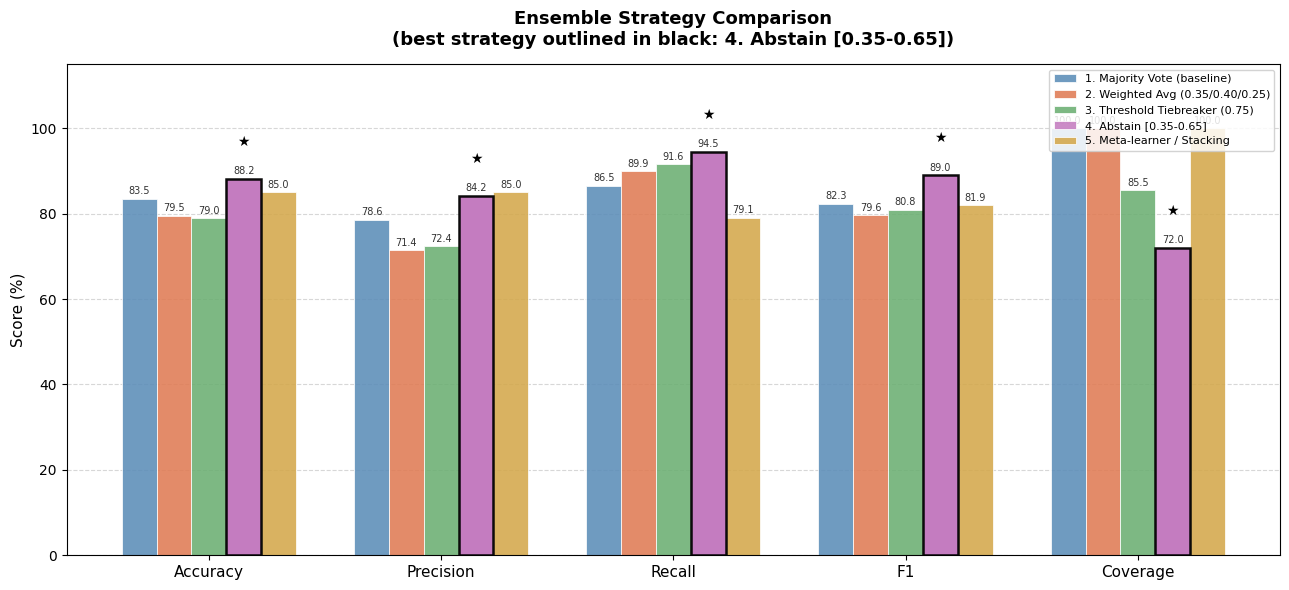


  DETAILED RESULTS TABLE
Strategy                                     Acc    Prec     Rec      F1     Cov    Abst
-------------------------------------------------------------------------------------
1. Majority Vote (baseline)                83.5%   78.6%   86.5%   82.3%  100.0%    0.0%
2. Weighted Avg (0.35/0.40/0.25)           79.5%   71.4%   89.9%   79.6%  100.0%    0.0%
3. Threshold Tiebreaker (0.75)             79.0%   72.4%   91.6%   80.8%   85.5%   14.5%
4. Abstain [0.35-0.65]                     88.2%   84.2%   94.5%   89.0%   72.0%   28.0% ◄ BEST
5. Meta-learner / Stacking                 85.0%   85.0%   79.1%   81.9%  100.0%    0.0%

  ✓ compute_final_verdict() remains frozen; no target-domain strategy was applied.
  All subsequent cells continue to use the parameter-free Majority Vote verdict.

Exploratory comparison complete.


In [ ]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from collections import Counter
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.linear_model import LogisticRegression
from scipy.sparse import vstack as sp_vstack
COMPARE_N       = 200
COMPARE_SEED    = 42
PHISHING_THRESH = 0.5
print("=" * 65)
print("  STEP 1 - collecting raw model outputs on comparison sample")
print("=" * 65)
sample_df = test_df.sample(n=min(COMPARE_N, len(test_df)),
                            random_state=COMPARE_SEED).reset_index(drop=True)
records = []
for _, row in sample_df.iterrows():
    email_text = str(row[EMAIL_COLUMN])
    gt         = int(row[LABEL_COLUMN])
    X_sparse = get_combined_features(email_text, row)
    X_dense  = X_sparse.toarray()
    svm_pred  = svm_linear_model.predict(X_sparse)[0]
    svm_score = svm_linear_model.decision_function(X_sparse)[0]
    svm_p     = 1.0 / (1.0 + np.exp(-svm_score))
    kern_pred  = svm_kernel_model.predict(X_sparse)[0]
    kern_proba = svm_kernel_model.predict_proba(X_sparse)[0]
    kern_p     = kern_proba[1]
    rf_pred  = rf_model.predict(X_dense)[0]
    rf_proba = rf_model.predict_proba(X_dense)[0]
    rf_p     = rf_proba[1]
    records.append({
        "gt":       gt,
        "svm_p":    svm_p,
        "kern_p":   kern_p,
        "rf_p":     rf_p,
        "svm_pred": svm_pred,
        "kern_pred": kern_pred,
        "rf_pred":  rf_pred,
    })
raw_df = pd.DataFrame(records)
print(f"Collected {len(raw_df)} samples. "
      f"Label distribution: {dict(raw_df['gt'].value_counts())}")
def strategy_majority_vote(df):
    preds = []
    for _, r in df.iterrows():
        votes = [int(r.svm_pred), int(r.kern_pred), int(r.rf_pred)]
        preds.append(Counter(votes).most_common(1)[0][0])
    return pd.Series(preds)
def strategy_weighted_avg(df, w_lin=0.35, w_kern=0.40, w_rf=0.25, thresh=PHISHING_THRESH):
    blended = w_lin * df.svm_p + w_kern * df.kern_p + w_rf * df.rf_p
    return (blended >= thresh).astype(int)
def strategy_tiebreaker(df, conf_thresh=0.75, thresh=PHISHING_THRESH):
    """
    Majority vote, but when models disagree AND at least one model's
    P(Phishing) exceeds conf_thresh → Phishing; otherwise abstain (-1).
    For metrics, abstains are treated as the majority-vote prediction
    so we can compare on the full sample.
    """
    preds = []
    for _, r in df.iterrows():
        votes = [int(r.svm_pred), int(r.kern_pred), int(r.rf_pred)]
        majority_label = Counter(votes).most_common(1)[0][0]
        majority_count = Counter(votes).most_common(1)[0][1]
        if majority_count == 3:
            preds.append(majority_label)
        else:
            max_p = max(r.svm_p, r.kern_p, r.rf_p)
            if max_p >= conf_thresh:
                preds.append(1)
            else:
                preds.append(-1)
    return pd.Series(preds)
def strategy_abstain(df, low=0.35, high=0.65,
                      w_lin=0.35, w_kern=0.40, w_rf=0.25):
    """
    Weighted blend → if in [low, high] → abstain (-1),
    else label by threshold.
    """
    blended = w_lin * df.svm_p + w_kern * df.kern_p + w_rf * df.rf_p
    labels  = []
    for p in blended:
        if p < low:
            labels.append(0)
        elif p > high:
            labels.append(1)
        else:
            labels.append(-1)
    return pd.Series(labels)
def strategy_stacking(df, raw_df_full):
    """
    Logistic Regression meta-learner trained on the first half,
    evaluated on the second half (avoids label leakage).
    Returns predictions aligned to the FULL df index so metrics
    are computed on the hold-out half only.
    """
    n      = len(raw_df_full)
    half   = n // 2
    X_meta = raw_df_full[["svm_p", "kern_p", "rf_p"]].values
    y_meta = raw_df_full["gt"].values
    X_train, X_test = X_meta[:half], X_meta[half:]
    y_train, y_test = y_meta[:half], y_meta[half:]
    meta = LogisticRegression(max_iter=1000)
    meta.fit(X_train, y_train)
    y_pred_half = meta.predict(X_test)
    full_preds = pd.Series([-1] * n)
    full_preds.iloc[half:] = y_pred_half
    return full_preds, half
print()
print("=" * 65)
print("  STEP 2 - evaluating all strategies")
print("=" * 65)
def evaluate(y_true, y_pred, label=""):
    """Compute metrics, ignoring abstain (-1) predictions."""
    mask   = y_pred != -1
    n_abstain = (~mask).sum()
    yt     = y_true[mask]
    yp     = y_pred[mask]
    if len(yt) == 0:
        return {"label": label, "accuracy": 0, "precision": 0,
                "recall": 0, "f1": 0, "coverage": 0, "abstain_pct": 100}
    return {
        "label":       label,
        "accuracy":    round(accuracy_score(yt, yp) * 100, 2),
        "precision":   round(precision_score(yt, yp, zero_division=0) * 100, 2),
        "recall":      round(recall_score(yt, yp, zero_division=0) * 100, 2),
        "f1":          round(f1_score(yt, yp, zero_division=0) * 100, 2),
        "coverage":    round(mask.mean() * 100, 2),
        "abstain_pct": round(n_abstain / len(y_pred) * 100, 2),
    }
y_true = raw_df["gt"]
results = []
mv_pred = strategy_majority_vote(raw_df)
results.append(evaluate(y_true, mv_pred, "1. Majority Vote (baseline)"))
wa_pred = strategy_weighted_avg(raw_df)
results.append(evaluate(y_true, wa_pred, "2. Weighted Avg (0.35/0.40/0.25)"))
tb_pred = strategy_tiebreaker(raw_df, conf_thresh=0.75)
results.append(evaluate(y_true, tb_pred, "3. Threshold Tiebreaker (0.75)"))
ab_pred = strategy_abstain(raw_df)
results.append(evaluate(y_true, ab_pred, "4. Abstain [0.35-0.65]"))
stack_pred, split_idx = strategy_stacking(raw_df, raw_df)
mask_stack = stack_pred != -1
yt_stack   = y_true[mask_stack]
yp_stack   = stack_pred[mask_stack]
results.append(evaluate(yt_stack.reset_index(drop=True),
                         yp_stack.reset_index(drop=True),
                         "5. Meta-learner / Stacking"))
results_df_cmp = pd.DataFrame(results).set_index("label")
print()
print(results_df_cmp.to_string())
print()
print("=" * 65)
print("  STEP 3 - selecting best strategy")
print("=" * 65)
ranked = results_df_cmp.sort_values(["f1", "accuracy"], ascending=False)
best_label = ranked.index[0]
best_row   = ranked.iloc[0]
print(f"\n  Best strategy : {best_label}")
print(f"  F1            : {best_row['f1']}%")
print(f"  Accuracy      : {best_row['accuracy']}%")
print(f"  Precision     : {best_row['precision']}%")
print(f"  Recall        : {best_row['recall']}%")
print(f"  Coverage      : {best_row['coverage']}%")
APPLY_BEST = False
BEST_STRATEGY_LABEL = best_label
print()
print("=" * 65)
print("  NOTE: auto-update of compute_final_verdict() is DISABLED")
print(f"  Best strategy by Enron sample : {best_label}")
print("  compute_final_verdict() remains Majority Vote (parameter-free).")
print("=" * 65)
if APPLY_BEST:
    raise RuntimeError(
        "APPLY_BEST=True is disabled for zero-shot OOD evaluation. "
        "Keep APPLY_BEST=False so compute_final_verdict() remains the "
        "frozen Majority Vote implementation from the earlier cell."
    )
print("  compute_final_verdict() remains the frozen Majority Vote implementation.")
print()
print("=" * 65)
print("  STEP 5 - plotting comparison chart")
print("=" * 65)
metrics   = ["accuracy", "precision", "recall", "f1", "coverage"]
labels    = results_df_cmp.index.tolist()
n_strat   = len(labels)
n_metrics = len(metrics)
x       = np.arange(n_metrics)
width   = 0.15
offsets = np.linspace(-(n_strat-1)/2 * width, (n_strat-1)/2 * width, n_strat)
colors  = ["#5B8DB8", "#E07B54", "#6BAF72", "#C47CC0", "#D4A84B"]
fig, ax = plt.subplots(figsize=(13, 6))
for i, (lbl, color) in enumerate(zip(labels, colors)):
    vals = [results_df_cmp.loc[lbl, m] for m in metrics]
    bars = ax.bar(x + offsets[i], vals, width, label=lbl,
                  color=color, alpha=0.88, edgecolor="white", linewidth=0.6)
    for bar, val in zip(bars, vals):
        ax.text(bar.get_x() + bar.get_width() / 2,
                bar.get_height() + 0.6,
                f"{val:.1f}", ha="center", va="bottom",
                fontsize=7, color="#333333")
best_idx = labels.index(best_label)
for j, m in enumerate(metrics):
    ax.bar(x[j] + offsets[best_idx],
           results_df_cmp.loc[best_label, m],
           width, color=colors[best_idx],
           edgecolor="black", linewidth=1.8, alpha=0.95)
ax.set_xticks(x)
ax.set_xticklabels([m.capitalize() for m in metrics], fontsize=11)
ax.set_ylabel("Score (%)", fontsize=11)
ax.set_ylim(0, 115)
ax.set_title("Ensemble Strategy Comparison\n"
             f"(best strategy outlined in black: {best_label})",
             fontsize=13, fontweight="bold", pad=14)
ax.legend(loc="upper right", fontsize=8, framealpha=0.85)
ax.yaxis.grid(True, linestyle="--", alpha=0.5)
ax.set_axisbelow(True)
for j in range(n_metrics):
    y_top = results_df_cmp.loc[best_label, metrics[j]] + 5
    ax.text(x[j] + offsets[best_idx], y_top + 2, "★",
            ha="center", va="bottom", fontsize=10, color="black")
plt.tight_layout()
plt.show()
plt.close(fig)
print()
print("=" * 65)
print("  DETAILED RESULTS TABLE")
print("=" * 65)
print(f"{'Strategy':<40} {'Acc':>7} {'Prec':>7} {'Rec':>7} {'F1':>7} {'Cov':>7} {'Abst':>7}")
print("-" * 85)
for lbl, row in results_df_cmp.iterrows():
    marker = " ◄ BEST" if lbl == best_label else ""
    print(f"{lbl:<40} {row.accuracy:>6.1f}% {row.precision:>6.1f}% "
          f"{row.recall:>6.1f}% {row.f1:>6.1f}% "
          f"{row.coverage:>6.1f}% {row.abstain_pct:>6.1f}%{marker}")
print("=" * 65)
print("\n  ✓ compute_final_verdict() remains frozen; no target-domain strategy was applied.")
print("  All subsequent cells continue to use the parameter-free Majority Vote verdict.")
print("\nExploratory comparison complete.")

## SHAP Feature Importance - Global Attribution Analysis

Computing SVM (linear) SHAP values over sample set...
Computing SVM (kernel) SHAP values over sample set...


  0%|          | 0/150 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_least_angle.py:723: ConvergenceWarning: Regressors in active set degenerate. Dropping a regressor, after 6 iterations, i.e. alpha=1.588e-01, with an active set of 6 regressors, and the smallest cholesky pivot element being 2.220e-16. Reduce max_iter or increase eps parameters.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_least_angle.py:723: ConvergenceWarning: Regressors in active set degenerate. Dropping a regressor, after 7 iterations, i.e. alpha=6.992e-02, with an active set of 7 regressors, and the smallest cholesky pivot element being 2.220e-16. Reduce max_iter or increase eps parameters.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/shap/explainers/_kernel.py:788: UserWarning: Linear regression equation is singular, a least squares solutions is used instead.
To avoid this situation and get a regular matrix do one of the following:
1) turn up the number of samples,
2) turn up

Computing RF SHAP values over sample set...


 97%|=================== | 292/300 [00:14<00:00]       


Top 25 features by mean |SHAP| (SVM linear + SVM kernel + RF combined):
               feature  svm_mean_abs_shap  kernel_mean_abs_shap  rf_mean_abs_shap  combined_rank_score
   writing_error_total           0.069068          2.078777e-02          0.017852             1.789542
          text_entropy           0.062848          1.746442e-02          0.018029             1.717896
        action_density           0.047604          6.105200e-02          0.016156             1.426597
       avg_word_length           0.045451          1.357566e-03          0.013842             1.282647
                  also           0.004948          1.413344e+12          0.002203             1.174550
                thanks           0.064431          1.226169e-03          0.006620             1.166144
                    pm           0.027908          6.691731e-04          0.013427             1.034760
repeated_char_patterns           0.001583          6.672701e-04          0.019937             1.020493


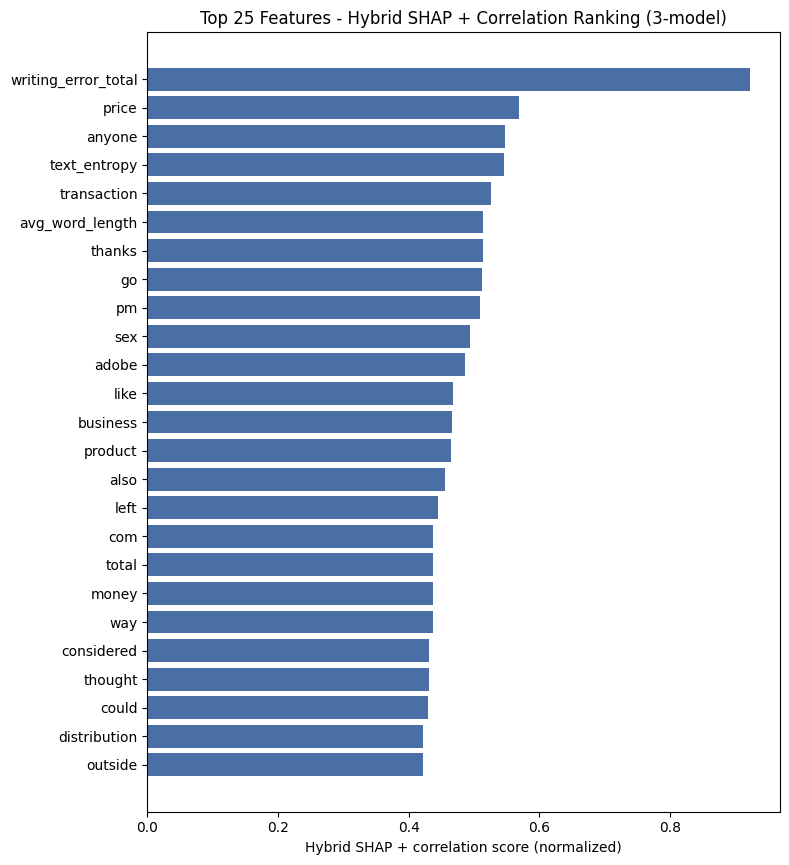


Full importance table and hybrid ranking saved.


In [ ]:
import numpy as np
import pandas as pd
from scipy.sparse import vstack
N_SAMPLE = 150
TOP_N = 25
sample_subset = test_df.sample(n=min(N_SAMPLE, len(test_df)), random_state=42)
sample_emails = sample_subset[EMAIL_COLUMN].tolist()
sample_sparse = vstack([
    get_combined_features(e, row)
    for e, (_, row) in zip(sample_emails, sample_subset.iterrows())
])
sample_dense  = sample_sparse.toarray()
def safe_shap_matrix(vals):
    arr = np.asarray(vals, dtype=object)
    if isinstance(vals, list) and len(vals) > 1:
        arr = np.asarray(vals[1])
    arr = np.asarray(arr, dtype=float)
    if arr.ndim == 3:
        arr = arr[..., -1] if arr.shape[-1] in [1, 2] else arr.reshape(arr.shape[0], -1)
    return arr
print("Computing SVM (linear) SHAP values over sample set...")
svm_shap_matrix = safe_shap_matrix(
    svm_explainer.shap_values(sample_sparse)
)
print("Computing SVM (kernel) SHAP values over sample set...")
svm_kernel_shap_matrix = safe_shap_matrix(
    svm_kernel_explainer.shap_values(sample_dense, nsamples=KERNEL_SHAP_NSAMPLES)
)
print("Computing RF SHAP values over sample set...")
rf_shap_matrix = safe_shap_matrix(rf_explainer.shap_values(sample_dense, check_additivity=False))
svm_importance    = np.abs(svm_shap_matrix).mean(axis=0)
kernel_importance = np.abs(svm_kernel_shap_matrix).mean(axis=0)
rf_importance     = np.abs(rf_shap_matrix).mean(axis=0)
importance_df = pd.DataFrame({
    "feature": all_feature_names,
    "svm_mean_abs_shap":    svm_importance,
    "kernel_mean_abs_shap": kernel_importance,
    "rf_mean_abs_shap":     rf_importance,
})
importance_df["combined_rank_score"] = (
    importance_df["svm_mean_abs_shap"]    / (importance_df["svm_mean_abs_shap"].max() or 1) +
    importance_df["kernel_mean_abs_shap"] / (importance_df["kernel_mean_abs_shap"].max() or 1) +
    importance_df["rf_mean_abs_shap"]     / (importance_df["rf_mean_abs_shap"].max() or 1)
)
top_features_df = importance_df.sort_values("combined_rank_score", ascending=False).head(TOP_N)
print(f"\nTop {TOP_N} features by mean |SHAP| (SVM linear + SVM kernel + RF combined):")
print(top_features_df.to_string(index=False))
sample_labels = test_df.loc[test_df[EMAIL_COLUMN].isin(sample_emails), LABEL_COLUMN].values
if len(sample_labels) != sample_dense.shape[0]:
    sample_labels = np.array([
        test_df.loc[test_df[EMAIL_COLUMN] == e, LABEL_COLUMN].iloc[0] for e in sample_emails
    ])
feature_matrix_df = pd.DataFrame(sample_dense, columns=all_feature_names)
feature_matrix_df["__label__"] = sample_labels
corr_with_label = feature_matrix_df.corr(numeric_only=True)["__label__"].drop("__label__")
importance_df["abs_correlation"] = importance_df["feature"].map(corr_with_label.abs())
importance_df["hybrid_score"] = (
    importance_df["combined_rank_score"] / (importance_df["combined_rank_score"].max() or 1) * 0.5 +
    importance_df["abs_correlation"].fillna(0) / (importance_df["abs_correlation"].max() or 1) * 0.5
)
hybrid_top_df = importance_df.sort_values("hybrid_score", ascending=False).head(TOP_N)
print(f"\nTop {TOP_N} features - hybrid SHAP + correlation ranking:")
print(hybrid_top_df[["feature","svm_mean_abs_shap","kernel_mean_abs_shap",
                      "rf_mean_abs_shap","abs_correlation","hybrid_score"]].to_string(index=False))
plt.figure(figsize=(8, max(4, 0.35 * TOP_N)))
plot_df = hybrid_top_df.sort_values("hybrid_score")
plt.barh(plot_df["feature"], plot_df["hybrid_score"], color="#4a6fa5")
plt.xlabel("Hybrid SHAP + correlation score (normalized)")
plt.title(f"Top {TOP_N} Features - Hybrid SHAP + Correlation Ranking (3-model)")
plt.tight_layout()
plt.savefig("/content/drive/MyDrive/Phishing_Email/results/enron_shap_correlation_top_features_kernel.png", dpi=150)
plt.show()
import os
os.makedirs("/content/drive/MyDrive/Phishing_Email/results", exist_ok=True)
importance_df.to_csv(
    "/content/drive/MyDrive/Phishing_Email/results/enron_kernel_shap_feature_importance_full_kernel.csv", index=False
)
hybrid_top_df.to_csv(
    "/content/drive/MyDrive/Phishing_Email/results/enron_kernel_shap_correlation_top_features_kernel.csv", index=False
)
print("\nFull importance table and hybrid ranking saved.")

## Adversarial Vulnerability Analysis (Synonym and Homoglyph Attacks)

In [ ]:


SYNONYM_MAP = {
    "urgent":    "time-sensitive",
    "verify":    "confirm",
    "account":   "profile",
    "suspend":   "deactivate",
    "click":     "select",
    "login":     "sign in",
    "password":  "passphrase",
    "update":    "refresh",
}

def synonym_attack(text):
    for orig, replacement in SYNONYM_MAP.items():
        text = re.sub(rf'\b{orig}\b', replacement, text, flags=re.IGNORECASE)
    return text

def homoglyph_attack(text):
    return text.replace('o','0').replace('l','1').replace('e','3')

phishing_subset  = test_df[test_df[LABEL_COLUMN] == 1].head(5)
phishing_samples = phishing_subset[EMAIL_COLUMN].tolist()
phishing_rows    = [row for _, row in phishing_subset.iterrows()]

print("=" * 65)
print("  PRE-ATTACK CORRECTNESS CHECK (ASR DENOMINATOR)")
print("=" * 65)

correctly_before = []
for idx_chk, (orig_text, orig_row) in enumerate(zip(phishing_samples, phishing_rows)):
    result_before = analyze_email_fast(orig_text, background_data, precomputed_row=orig_row)
    is_correct = (result_before["final_label"] == "Phishing")
    correctly_before.append(is_correct)
    status = "COUNTS IN ASR" if is_correct else "EXCLUDE (already wrong)"
    print(f"  Email {idx_chk+1}: {result_before['final_label']} → {status}")

valid_asr_denominator = sum(correctly_before)
print(f"\nValid ASR denominator: {valid_asr_denominator} / 5")
print("=" * 65)

syn_evaded_k3  = 0
homo_evaded_k3 = 0

print("\n" + "=" * 65)
print("  ADVERSARIAL VULNERABILITY PROBE")
print("=" * 65)

for i, (original, orig_row, was_correct) in enumerate(
        zip(phishing_samples, phishing_rows, correctly_before)):
    syn_attacked  = synonym_attack(original)
    homo_attacked = homoglyph_attack(original)

    orig_result = analyze_email_fast(original, background_data, precomputed_row=orig_row)
    syn_result  = analyze_email_fast(syn_attacked, background_data)
    homo_result = analyze_email_fast(homo_attacked, background_data)

    syn_evaded  = was_correct and syn_result["final_label"]  != "Phishing"
    homo_evaded = was_correct and homo_result["final_label"] != "Phishing"
    if syn_evaded:  syn_evaded_k3  += 1
    if homo_evaded: homo_evaded_k3 += 1

    print(f"\n--- Email {i+1} (counts in ASR: {was_correct}) ---")
    print(f"Original       : {orig_result['final_label']} ({orig_result['final_confidence']}%)")
    print(f"Synonym attack : {syn_result['final_label']}  ({syn_result['final_confidence']}%)"
          + (" ← EVADED" if syn_evaded else ""))
    print(f"Homoglyph atk  : {homo_result['final_label']}  ({homo_result['final_confidence']}%)"
          + (" ← EVADED" if homo_evaded else ""))
    print(f"SHAP consistency - Original: {orig_result['shap_consistency']}%  "
          f"| Synonym: {syn_result['shap_consistency']}%  "
          f"| Homoglyph: {homo_result['shap_consistency']}%")
    print(f"Evaded by synonym:    {syn_result['final_label']  != 'Phishing'}")
    print(f"Evaded by homoglyph:  {homo_result['final_label'] != 'Phishing'}")

print("\n" + "=" * 65)
print("  ADVERSARIAL VULNERABILITY PROBE - RUNTIME ASR")
print("=" * 65)
print(f"  Valid denominator (correct before attack): {valid_asr_denominator} / 5")
if valid_asr_denominator > 0:
    print(f"  Synonym ASR   : {syn_evaded_k3} / {valid_asr_denominator} = {syn_evaded_k3/valid_asr_denominator*100:.1f}%")
    print(f"  Homoglyph ASR : {homo_evaded_k3} / {valid_asr_denominator} = {homo_evaded_k3/valid_asr_denominator*100:.1f}%")
print()
print("=" * 65)


  PRE-ATTACK CORRECTNESS CHECK (ASR DENOMINATOR)


  0%|          | 0/1 [00:00<?, ?it/s]

  Email 1: Phishing → COUNTS IN ASR


  0%|          | 0/1 [00:00<?, ?it/s]

  Email 2: Legitimate → EXCLUDE (already wrong)


  0%|          | 0/1 [00:00<?, ?it/s]

... (27 outputs left out)

  0%|          | 0/1 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_least_angle.py:723: ConvergenceWarning: Regressors in active set degenerate. Dropping a regressor, after 9 iterations, i.e. alpha=2.760e-02, with an active set of 8 regressors, and the smallest cholesky pivot element being 2.220e-16. Reduce max_iter or increase eps parameters.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/shap/explainers/_kernel.py:788: UserWarning: Linear regression equation is singular, a least squares solutions is used instead.
To avoid this situation and get a regular matrix do one of the following:
1) turn up the number of samples,
2) turn up the L1 regularization with num_features(N) where N is less than the number of samples,
3) group features together to reduce the number of inputs that need to be explained.
  warnings.warn(


  0%|          | 0/1 [00:00<?, ?it/s]


--- Email 5 (counts in ASR: True) ---
Original       : Phishing (84.3%)
Synonym attack : Legitimate  (73.7%) ← EVADED
Homoglyph atk  : Legitimate  (71.7%) ← EVADED
SHAP consistency - Original: 44.1%  | Synonym: 43.5%  | Homoglyph: 40.3%
Evaded by synonym:    True
Evaded by homoglyph:  True

  ADVERSARIAL VULNERABILITY PROBE - RUNTIME ASR
  Valid denominator (correct before attack): 4 / 5
  Synonym ASR   : 4 / 4 = 100.0%
  Homoglyph ASR : 4 / 4 = 100.0%



## Multi-Label Phishing-Tactic Classifier

In [ ]:
from sklearn.multiclass import OneVsRestClassifier
from sklearn.svm import LinearSVC
from sklearn.preprocessing import MultiLabelBinarizer
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report
from scipy.sparse import vstack

TACTIC_KEYWORDS = {
    "Urgency":    ["urgent","immediately","expire","limited","asap","hours"],
    "Financial":  ["payment","invoice","transfer","refund","reward","prize"],
    "Authority":  ["bank","paypal","amazon","microsoft","government","irs"],
    "Credential": ["verify","login","password","account","confirm","update"],
    "Fear":       ["suspended","locked","blocked","unauthorized","breach"],
    "Attachment": ["attachment","open","download","pdf","doc","file"],
    "Link":       ["click here","click below","here","link","visit"],
}

def auto_label_tactics(text):
    text_lower = text.lower()
    return [tactic for tactic, kws in TACTIC_KEYWORDS.items()
            if any(kw in text_lower for kw in kws)]

phishing_df = test_df[test_df[LABEL_COLUMN] == 1].copy().reset_index(drop=True)
phishing_df["tactics"] = phishing_df[EMAIL_COLUMN].apply(auto_label_tactics)
phishing_df = phishing_df[phishing_df["tactics"].map(len) > 0].reset_index(drop=True)

print(f"Phishing emails with at least one tactic label: {len(phishing_df)}")

mlb = MultiLabelBinarizer()
Y_tactic = mlb.fit_transform(phishing_df["tactics"])
X_tactic = vstack([
    get_combined_features(str(row[EMAIL_COLUMN]), row)
    for _, row in phishing_df.iterrows()
])

Xt_train, Xt_test, Yt_train, Yt_test = train_test_split(
    X_tactic, Y_tactic, test_size=0.2, random_state=42)

tactic_clf = OneVsRestClassifier(LinearSVC(C=1.0, max_iter=5000))
tactic_clf.fit(Xt_train, Yt_train)

pred_tactics = tactic_clf.predict(Xt_test)
print("\n=== TACTIC CLASSIFIER RESULTS ===")
print(classification_report(Yt_test, pred_tactics, target_names=mlb.classes_))

sample_email = phishing_df[EMAIL_COLUMN].iloc[0]
sample_features = get_combined_features(sample_email, phishing_df[phishing_df[EMAIL_COLUMN] == sample_email].iloc[0])
predicted_tactics = mlb.inverse_transform(tactic_clf.predict(sample_features))[0]
print(f"\nSample email preview: {sample_email[:150]}...")
print(f"Predicted tactics: {list(predicted_tactics)}")

Phishing emails with at least one tactic label: 8166

=== TACTIC CLASSIFIER RESULTS ===
              precision    recall  f1-score   support

  Attachment       0.89      0.82      0.86       624
   Authority       0.92      0.84      0.88       570
  Credential       0.94      0.86      0.90       431
        Fear       0.89      0.60      0.71        52
   Financial       0.96      0.81      0.88       300
        Link       0.86      0.88      0.87      1035
     Urgency       0.93      0.79      0.85       375

   micro avg       0.90      0.84      0.87      3387
   macro avg       0.91      0.80      0.85      3387
weighted avg       0.91      0.84      0.87      3387
 samples avg       0.86      0.83      0.83      3387


Sample email preview: dwl g high speed ghz g wireless pci lanadapterieee g standardupto mbpsoperating frequency range ghz ideal solution enabling wireless networkingcapabil...
Predicted tactics: ['Attachment', 'Authority', 'Link', 'Urgency']


/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in samples with no predicted labels. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
